In [1]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import multiprocess as mp
import numpy as np
import pandas as pd
import bioframe as bf
import cooltools
import cooler
from matplotlib import gridspec
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
from collections import OrderedDict
import plotly.express as px
import plotly.graph_objects as go
from matplotlib.cm import ScalarMappable
from scipy.ndimage import gaussian_filter
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import euclidean_distances
from sklearn.decomposition import PCA
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.stats import pearsonr
import os


import sklearn.cluster as cl
#import hdbscan as hdbscan
import umap
from ismember import ismember


# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:651: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:726: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)
/home/xiangru.huo-um

In [2]:
#read the gene variable VS bulk expression VS genome variability table
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']
gene_bin_selected = {}

for stage in stages:
    file_path = f"/home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bin_bulk_{stage}.csv"
    gene_bin_selected[stage] = pd.read_csv(file_path, sep=',')

In [3]:
#read the UMI matrix to remove the drop out 
# Load UMI matrix and transpose
UMI_matrix = pd.read_csv("/home/xiangru.huo-umw/SSC/Matrix/4DN_5stage_fresh/4DN_fresh_5stages_reads_all_matrix.txt",sep='\t', index_col=0).transpose()
# Replace 'H1' prefix with 'ES' in the index
UMI_matrix.index = UMI_matrix.index.to_series().apply(lambda x: x.replace('H1.', 'ES.', 1) if x.startswith('H1.') else x)

# Define your stages
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']
gene_bin = {}

for stage in stages:
    # Select rows belonging to this stage (assumes index format like 'stage.cellID')
    stage_rows = [idx for idx in UMI_matrix.index if idx.split('.')[0] == stage]
    stage_UMI = UMI_matrix.loc[stage_rows]
    # Calculate gene-wise dropout ratio
    dropout_ratio = (stage_UMI == 0).sum(axis=0) / stage_UMI.shape[0]
    
    # Wrap in DataFrame
    dropout_df = dropout_ratio.to_frame(name='dropout_ratio')
    dropout_df['gene'] = dropout_df.index

    # Merge with gene_bin_selected
    df1 = gene_bin_selected[stage].copy()
    df1 = df1.merge(dropout_df, on='gene', how='left')

    # Save result
    output_path = f"/home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bin_bulk_scdropout_{stage}.csv"
    df1.to_csv(output_path, index=False)

    # Store in dictionary
    gene_bin[stage] = df1

In [10]:
#read the structure features tables
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']

genomic_features_selected = {}

for stage in stages:
    # read structure features
    struct_path = f"/home/xiangru.huo-umw/scHiC/scripts/structure_feature_model/{stage}_structual_features_actual_nuc.csv"
    struct_df = pd.read_csv(struct_path)

    # read locale entropy features
    entropy_path = f"/home/xiangru.huo-umw/scHiC/scripts/structure_feature_model/{stage}_cisCV_locale_entropy_filtered.csv"
    entropy_df = pd.read_csv(entropy_path)

    # merge by genomic coordinates
    merged_df = pd.merge(
        struct_df,
        entropy_df,
        on=["chr", "start", "end"],
        how="inner"
    )

    genomic_features_selected[stage] = merged_df

    # optional: save
    out_path = f"/home/xiangru.huo-umw/scHiC/scripts/structure_feature_model/{stage}_structural_locale_entropy_merged.csv"
    merged_df.to_csv(out_path, index=False)

    print(stage, merged_df.shape)

ES (11457, 32)
DE (11457, 32)
HB (11457, 32)
iHep (11457, 32)
mHep (11457, 32)


In [11]:
genomic_features_selected[stage]

,chr,start,end,rad,rad_std,delta_rad,norm_rad,norm_rad_std,delta_norm_rad,trans_count_S.D._model,...,rg,rgsd,icp,icpsd,transab,transabsd,tag,domain,cisratioCV,entropy
0,chr1,600000,800000,3174.393962,1042.586860,-0.083930,0.550562,0.147371,0.157856,12.451896,...,NaN,NaN,0.524173,0.204377,0.708229,0.237352,NaN,domain,0.281680,1.699551
1,chr1,4200000,4400000,3164.311602,1022.546689,-0.103339,0.546545,0.145897,0.147806,12.775064,...,303.429202,34.895758,0.586439,0.210020,0.650429,0.231861,B1,domain,0.353874,2.094798
2,chr1,4800000,5000000,3184.710116,1019.536466,-0.106287,0.565815,0.148095,0.162761,12.411306,...,281.261171,42.084816,0.552365,0.217898,0.598779,0.250890,B1,domain,0.346253,2.161651
3,chr1,5000000,5200000,3193.547584,1017.986851,-0.107808,0.567638,0.146241,0.150161,12.915183,...,293.248617,44.061231,0.567599,0.221505,0.602567,0.252867,B1,domain,0.360313,2.154932
4,chr1,5200000,5400000,3197.192089,1015.946041,-0.109815,0.570594,0.146309,0.150627,12.434973,...,290.332947,48.510863,0.551686,0.219059,0.599120,0.254255,B1,domain,0.332619,2.153921
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11452,chr22,39800000,40000000,3415.244586,1042.871936,-0.083657,0.580703,0.135014,0.070281,10.143787,...,300.956948,34.551581,0.725943,0.120354,0.772012,0.186317,B1,domain,0.304768,1.747632
11453,chr22,40000000,40200000,3425.019810,1041.972788,-0.084519,0.587935,0.136398,0.080485,10.258969,...,300.708065,36.155575,0.705296,0.122906,0.772597,0.185191,A1,domain,0.291948,1.732405
11454,chr22,43600000,43800000,3364.178936,1043.895869,-0.082675,0.574490,0.141884,0.119918,10.163613,...,320.865656,37.476376,0.721864,0.127136,0.690626,0.207107,B1,domain,0.323660,2.116505
11455,chr22,44400000,44600000,3353.555605,1037.423257,-0.088895,0.579036,0.140931,0.113173,10.072101,...,295.697247,30.987035,0.705963,0.126257,0.700217,0.204359,B1,domain,0.292124,2.045112


In [12]:
#read gene table
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']
gene_selected = {}

for stage in stages:
    file_path = f"/home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bincluster_annotate_{stage}.txt"
    gene_selected[stage] = pd.read_csv(file_path, sep='\t', index_col=0)

In [13]:
gene_selected[stage]

,chrom_1,start_1,end_1,gene_1,dot_1,strand_1,chrom_2,start_2,end_2,Cluster_2,E1_2,cisratio_mean_2,cisratio_cv_2,bin_ID_2
0,chr5,58197.0,58198.0,AC113430.1,.,+,chr5,0,1000000,1,0.589199,0.814060,0.219134,chr5_Bin0
1,chr5,92150.0,92151.0,PLEKHG4B,.,+,chr5,0,1000000,1,0.589199,0.814060,0.219134,chr5_Bin0
2,chr5,191510.0,191511.0,LRRC14B,.,+,chr5,0,1000000,1,0.589199,0.814060,0.219134,chr5_Bin0
3,chr5,195777.0,195778.0,AC021087.3,.,+,chr5,0,1000000,1,0.589199,0.814060,0.219134,chr5_Bin0
4,chr5,217278.0,217279.0,AC021087.2,.,-,chr5,0,1000000,1,0.589199,0.814060,0.219134,chr5_Bin0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52611,chr16,89921391.0,89921392.0,TUBB3,.,+,chr16,89000000,90000000,2,0.689251,0.853337,0.125578,chr16_Bin89
52612,chr16,89922661.0,89922662.0,AC092143.2,.,-,chr16,89000000,90000000,2,0.689251,0.853337,0.125578,chr16_Bin89
52613,chr16,89947924.0,89947925.0,DEF8,.,+,chr16,89000000,90000000,2,0.689251,0.853337,0.125578,chr16_Bin89
52614,chr16,89972585.0,89972586.0,AFG3L1P,.,+,chr16,89000000,90000000,2,0.689251,0.853337,0.125578,chr16_Bin89


In [14]:
#merge gene table with the model feature
# === Loop through stages ===
overlap_results = {}

for stage in ['ES', 'DE', 'HB', 'iHep', 'mHep']:
    df_features = genomic_features_selected[stage].copy()
    df_genes = gene_selected[stage].copy()

    # --- standardize column names for bioframe ---
    df_features = df_features.rename(columns={"chr": "chrom", "start": "start", "end": "end"})
    df_genes = df_genes.rename(columns={"chrom_1": "chrom", "start_1": "start", "end_1": "end"})
    for col in ["start", "end"]:
        df_genes[col] = pd.to_numeric(df_genes[col], errors="coerce").astype("Int64")

    # --- perform overlap ---
    overlap = bf.overlap(df_genes,df_features,how="left",suffixes=("_gene", "_model"))

    # --- keep essential columns ---
    # ---- select what you actually have (based on your shown output) ----
    wanted = [
        # gene record (original gene interval)
        "chrom_1_gene", "start_1_gene", "end_1_gene", "gene_1_gene", 
        "Cluster_2_gene", "E1_2_gene", "cisratio_mean_2_gene", "cisratio_cv_2_gene", "bin_ID_2_gene",
        'chrom_model','start_model','end_model',
        "rad_model", "rad_std_model", "delta_rad_model",
        "norm_rad_model", "norm_rad_std_model", "delta_norm_rad_model", 'trans_count_S.D._model_model',
        "cisratio_mean_model_model", "cisratio_cv_model_model",
        "naf_model", "laf_model", "rg_model", "rgsd_model",
        "icp_model", "icpsd_model", "transab_model", "transabsd_model",
        "tag_model", "domain_model",    
        "entropy_model",
        "cisratioCV_model",
    ]
    
    # keep only those that exist
    keep_cols = [c for c in wanted if c in overlap.columns]
    overlap = overlap[keep_cols].copy()

    # ---- tidy names ----
    rename_map = {
        # gene record (original)
        "chrom_1_gene": "gene_chrom",
        "start_1_gene": "gene_start",
        "end_1_gene": "gene_end",
        "gene_1_gene": "gene",

        "Cluster_2_gene": "cluster",
        "E1_2_gene": "E1",
        "cisratio_mean_2_gene": "cisratio_mean_gene",
        "cisratio_cv_2_gene": "cisratio_cv_gene",
        "bin_ID_2_gene": "Bin_ID",

        'chrom_model':'chrom_model',
        'start_model':'start_model',
        'end_model':'end_model',
        "rad_model": "rad",
        "rad_std_model": "rad_std",
        "delta_rad_model": "delta_rad",
        "norm_rad_model": "norm_rad",
        "norm_rad_std_model": "norm_rad_std",
        "delta_norm_rad_model": "delta_norm_rad",
        "cisratio_mean_model_model": "cisratio_mean_model",
        "cisratio_cv_model_model": "cisratio_cv_model",
        "trans_count_S.D._model_model": "trans_count_S.D._model",
        "naf_model": "naf",
        "laf_model": "laf",
        "rg_model": "rg",
        "rgsd_model": "rgsd",
        "icp_model": "icp",
        "icpsd_model": "icpsd",
        "transab_model": "transab",
        "transabsd_model": "transabsd",
        "tag_model": "tag",
        "domain_model": "domain",
        "cisratioCV_model": "cisratioCV_with_entropy",
        "entropy_model": "entropy",
    }

    # apply only for columns that exist
    overlap.rename(columns={k: v for k, v in rename_map.items() if k in overlap.columns}, inplace=True)
    overlap_results[stage] = overlap

In [15]:
overlap_results[stage].columns

Index(['gene', 'cluster', 'E1', 'cisratio_mean_gene', 'cisratio_cv_gene',
       'Bin_ID', 'chrom_model', 'start_model', 'end_model', 'rad', 'rad_std',
       'delta_rad', 'norm_rad', 'norm_rad_std', 'delta_norm_rad',
       'trans_count_S.D._model', 'cisratio_mean_model', 'cisratio_cv_model',
       'naf', 'laf', 'rg', 'rgsd', 'icp', 'icpsd', 'transab', 'transabsd',
       'tag', 'domain', 'entropy', 'cisratioCV_with_entropy'],
      dtype='object')

In [16]:
#read the old gene_merged structure table
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']
gene_bin_selected = {}

for stage in stages:
    file_path = f"/home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bin_bulk_scdropout_{stage}.csv"
    gene_bin_selected[stage] = pd.read_csv(file_path)

In [17]:
#merge the genes table with the newest genomic bin table
# === Remove model related columns across all stages ===
cols_to_remove = [
    'chrom_bin', 'start_bin', 'end_bin', 'rad_bin', 'rad_std_bin', 'delta_rad_bin',
    'norm_rad_bin', 'norm_rad_std_bin', 'delta_norm_rad_bin',
    'trans_count_S.D._model_bin', 'cis_count_S.D._model_bin',
    'trans_count_mean_model_bin', 'cis_count_mean_model_bin',
    'norm_spd_bin', 'spd_bin', 'saf_bin', 'nud_bin', 'naf_bin', 'laf_bin',
    'tag_bin', 'domain_bin'
]

# === Loop over all stages ===
merged_results = {}

for stage in gene_bin_selected.keys():
    gene_bin_selected[stage].drop(
        columns=[c for c in cols_to_remove if c in gene_bin_selected[stage].columns],
        inplace=True
    )

    df_gene = gene_bin_selected[stage].copy()
    df_overlap = overlap_results[stage].copy()

    # Merge
    merged = pd.merge(
        df_gene,
        df_overlap,
        on="gene",
        how="right",
        suffixes=("", "_model"))
    merged_results[stage] = merged

    # Save
    file_path = f"/home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bin_bulk_scdropout_updated_{stage}.csv"
    merged.to_csv(file_path, index=False)

In [18]:
merged_results['ES'].columns

Index(['mean_expression', 'residual_variance', 'gene', 'stage', 'Bin_ID',
       'chrom', 'start', 'end', 'E1', 'cisratio_mean', 'cisratio_S.D.',
       'cisratio_cv', 'total_counts_Mean', 'total_counts_sum',
       'cis_counts_S.D.', 'total_counts_S.D.', 'rep1', 'rep2', 'bulk_tpm',
       'dropout_ratio', 'cluster', 'E1_model', 'cisratio_mean_gene',
       'cisratio_cv_gene', 'Bin_ID_model', 'chrom_model', 'start_model',
       'end_model', 'rad', 'rad_std', 'delta_rad', 'norm_rad', 'norm_rad_std',
       'delta_norm_rad', 'trans_count_S.D._model', 'cisratio_mean_model',
       'cisratio_cv_model', 'naf', 'laf', 'rg', 'rgsd', 'icp', 'icpsd',
       'transab', 'transabsd', 'tag', 'domain', 'entropy',
       'cisratioCV_with_entropy'],
      dtype='object')

In [19]:
# report how many genes used
for stage, df in merged_results.items():
    print(f"\n🔹 Stage: {stage}")

    # 1) Filter: drop rows where ANY of these is NaN
    df_clean = df.dropna(subset=["residual_variance", "rep1", "rep2"], how="all").copy()

    # 2) Recompute counts on the filtered table
    n_total_after = len(df_clean)
    n_valid_resvar = df_clean["residual_variance"].notna().sum()
    # valid if either rep1 or rep2 present (both are present after filtering, so == n_total_after)
    n_valid_rep = ((df_clean["rep1"].notna()) | (df_clean["rep2"].notna())).sum()

    print(f"  Total genes AFTER filtering (no NA in residual_variance/rep1/rep2): {n_total_after}")
    print(f"  scRNA-seq residual_variance valid: {n_valid_resvar} ({(n_valid_resvar / n_total_after if n_total_after else 0):.2%})")
    print(f"  bulk (rep1 or rep2) valid: {n_valid_rep} ({(n_valid_rep / n_total_after if n_total_after else 0):.2%})")

    # 3) Summarize missing values within bins (no bin listing)
    bin_stats = (
        df_clean.groupby("Bin_ID")
        .apply(lambda x: pd.Series({
            "all_resvar_NA": x["residual_variance"].isna().all(),
            "all_rep1_NA": x["rep1"].isna().all(),
            "all_rep2_NA": x["rep2"].isna().all()
        }))
    )

    # Count how many bins are entirely NA for each column
    n_bins_total = bin_stats.shape[0]
    n_bins_all_resvar_na = bin_stats["all_resvar_NA"].sum()
    n_bins_all_rep1_na   = bin_stats["all_rep1_NA"].sum()
    n_bins_all_rep2_na   = bin_stats["all_rep2_NA"].sum()

    print(f"  Total 1M Bins: {n_bins_total}")
    print(f"  Bins all missing residual_variance: {n_bins_all_resvar_na}")
    print(f"  Bins all missing bulk_tpm (rep1 & 2): {n_bins_all_rep1_na}")


🔹 Stage: ES
  Total genes AFTER filtering (no NA in residual_variance/rep1/rep2): 13869
  scRNA-seq residual_variance valid: 13869 (100.00%)
  bulk (rep1 or rep2) valid: 10018 (72.23%)
  Total 1M Bins: 1571
  Bins all missing residual_variance: 0
  Bins all missing bulk_tpm (rep1 & 2): 105

🔹 Stage: DE
  Total genes AFTER filtering (no NA in residual_variance/rep1/rep2): 20923
  scRNA-seq residual_variance valid: 20923 (100.00%)
  bulk (rep1 or rep2) valid: 14994 (71.66%)
  Total 1M Bins: 2477
  Bins all missing residual_variance: 0
  Bins all missing bulk_tpm (rep1 & 2): 208

🔹 Stage: HB
  Total genes AFTER filtering (no NA in residual_variance/rep1/rep2): 19000
  scRNA-seq residual_variance valid: 19000 (100.00%)
  bulk (rep1 or rep2) valid: 13646 (71.82%)
  Total 1M Bins: 2193
  Bins all missing residual_variance: 0
  Bins all missing bulk_tpm (rep1 & 2): 174

🔹 Stage: iHep
  Total genes AFTER filtering (no NA in residual_variance/rep1/rep2): 18968
  scRNA-seq residual_variance val

In [20]:
#200kb bins
per_locus_na = {}

for stage, df in merged_results.items():
    # --- make a locus key: chrom_model + "_" + start_model ---
    df2 = df.copy()
    df2["locus_id"] = (
        df2["chrom_model"].astype(str) + "_" +
        pd.to_numeric(df2["start_model"], errors="coerce").astype("Int64").astype(str)
    )

    # --- per-locus NA summary ---
    locus_stats = (
        df2.groupby("locus_id", dropna=False)
           .apply(lambda x: pd.Series({
               "n_genes": len(x),
               "all_resvar_NA": x["residual_variance"].isna().all(),
               "all_rep1_NA": x["rep1"].isna().all(),
               "all_rep2_NA": x["rep2"].isna().all(),
               "any_resvar_NA": x["residual_variance"].isna().any(),
               "any_rep1_NA": x["rep1"].isna().any(),
               "any_rep2_NA": x["rep2"].isna().any(),
           }))
           .reset_index()
    )

    # optional fractions
    locus_stats["frac_resvar_NA"] = (
        locus_stats["all_resvar_NA"].astype(int) / locus_stats["n_genes"]
    )

    # store table
    per_locus_na[stage] = locus_stats

    # --- summary counts ---
    n_loci_total = locus_stats["locus_id"].nunique()
    n_loci_all_resvar_na = int(locus_stats["all_resvar_NA"].sum())
    n_loci_all_rep1_na   = int(locus_stats["all_rep1_NA"].sum())
    n_loci_all_rep2_na   = int(locus_stats["all_rep2_NA"].sum())

    print(f"\n🔹 Stage: {stage}")
    print(f"  Total loci: {n_loci_total}")
    print(f"  Loci all missing residual_variance: {n_loci_all_resvar_na}")
    print(f"  Loci all missing bulk_tpm (rep1 & 2): {n_loci_all_rep1_na}")


🔹 Stage: ES
  Total loci: 6032
  Loci all missing residual_variance: 1685
  Loci all missing bulk_tpm (rep1 & 2): 2506

🔹 Stage: DE
  Total loci: 9075
  Loci all missing residual_variance: 2669
  Loci all missing bulk_tpm (rep1 & 2): 4004

🔹 Stage: HB
  Total loci: 8238
  Loci all missing residual_variance: 2396
  Loci all missing bulk_tpm (rep1 & 2): 3583

🔹 Stage: iHep
  Total loci: 8489
  Loci all missing residual_variance: 2500
  Loci all missing bulk_tpm (rep1 & 2): 3753

🔹 Stage: mHep
  Total loci: 9481
  Loci all missing residual_variance: 2804
  Loci all missing bulk_tpm (rep1 & 2): 4214


# load gene variance tables merged with dropout ratio, bulk expression, and genome variability

In [21]:
# Read gene variance tables merged with dropout ratio, bulk expression, and genome variability
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']
gene_bin_selected = {}

for stage in stages:
    file_path = f"/home/xiangru.huo-umw/scHiC/scripts/inter_file/gene_bin_bulk_scdropout_updated_{stage}.csv"
    gene_bin_selected[stage] = pd.read_csv(file_path)

In [22]:
gene_bin_selected['iHep']

,mean_expression,residual_variance,gene,stage,Bin_ID,chrom,start,end,E1,cisratio_mean,...,rg,rgsd,icp,icpsd,transab,transabsd,tag,domain,entropy,cisratioCV_with_entropy
0,NaN,NaN,AC113430.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.042553,0.260327,PLEKHG4B,iHep,chr5_Bin0,chr5,0.0,1000000.0,0.495368,0.844650,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,LRRC14B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,AC021087.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,AC021087.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45878,0.000000,0.000356,TUBB3,iHep,chr16_Bin89,chr16,89000000.0,90000000.0,0.678409,0.872842,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
45879,NaN,NaN,AC092143.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
45880,1.069149,1.461313,DEF8,iHep,chr16_Bin89,chr16,89000000.0,90000000.0,0.678409,0.872842,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
45881,0.010638,0.173052,AFG3L1P,iHep,chr16_Bin89,chr16,89000000.0,90000000.0,0.678409,0.872842,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
gene_bin_selected['iHep'].columns

Index(['mean_expression', 'residual_variance', 'gene', 'stage', 'Bin_ID',
       'chrom', 'start', 'end', 'E1', 'cisratio_mean', 'cisratio_S.D.',
       'cisratio_cv', 'total_counts_Mean', 'total_counts_sum',
       'cis_counts_S.D.', 'total_counts_S.D.', 'rep1', 'rep2', 'bulk_tpm',
       'dropout_ratio', 'cluster', 'E1_model', 'cisratio_mean_gene',
       'cisratio_cv_gene', 'Bin_ID_model', 'chrom_model', 'start_model',
       'end_model', 'rad', 'rad_std', 'delta_rad', 'norm_rad', 'norm_rad_std',
       'delta_norm_rad', 'trans_count_S.D._model', 'cisratio_mean_model',
       'cisratio_cv_model', 'naf', 'laf', 'rg', 'rgsd', 'icp', 'icpsd',
       'transab', 'transabsd', 'tag', 'domain', 'entropy',
       'cisratioCV_with_entropy'],
      dtype='object')

In [24]:
# Read the vst dispersion table
vst_dispersion = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/vst_dispersion_by_stage.csv", sep=',')
# Replace 'H1' with 'ES' in the 'stage' column
vst_dispersion['stage'] = vst_dispersion['stage'].replace('H1', 'ES')

# Split by stage
vst_dispersion_stage = {}
for stage in stages:
    df = vst_dispersion.copy()
    vst_dispersion_stage[stage] = df[df['stage'] == stage]

In [25]:
vst_dispersion_stage['HB']

,vst.mean,vst.variance,vst.variance.expected,vst.variance.standardized,gene,stage
64468,0.000000,0.000000,0.000000,0.000000,TSPAN6,HB
64469,0.000000,0.000000,0.000000,0.000000,TNMD,HB
64470,0.000000,0.000000,0.000000,0.000000,DPM1,HB
64471,0.021053,0.031300,0.026086,1.199911,SCYL3,HB
64472,0.021053,0.084211,0.026086,1.022282,C1orf112,HB
...,...,...,...,...,...,...
96697,0.000000,0.000000,0.000000,0.000000,KRTAP10-9,HB
96698,0.000000,0.000000,0.000000,0.000000,AC112492.2,HB
96699,0.000000,0.000000,0.000000,0.000000,AL034346.1,HB
96700,0.000000,0.000000,0.000000,0.000000,SMCO4P1,HB


In [26]:
#label the subcompartment annotation
#read the gene tss table
file_path = '/home/xiangru.huo-umw/scHiC/scripts/inter_file/filtered_gene_tss.bed'
# Read the .bed file into a DataFrame
gene_tss = pd.read_csv(file_path, sep='\t', index_col=0)
#Read file of subcompartment annotation
subcompartment_file = '/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/hepdiff.jointly_pca.norm.kmeans_10_7.labeled.tsv'
subcompartment = pd.read_csv(subcompartment_file, sep='\t')

gene_subcompartment = bf.overlap(gene_tss,subcompartment, how='left', suffixes=('_1','_2'))
# Select specific columns
gene_subcompartment = gene_subcompartment[['gene_1', 'name_2']]
# Rename columns
gene_subcompartment.rename(columns={'gene_1': 'gene', 'name_2': 'subcompartment'}, inplace=True)

gene_subcompartment

,gene,subcompartment
0,DDX11L1,NaN
1,MIR6859-1,NaN
2,MIR1302-2HG,NaN
3,WASH7P,NaN
4,MIR1302-2,NaN
...,...,...
57128,AMD1P2,None
57129,ELOCP24,None
57130,TRPC6P,None
57131,WASIR1,None


In [27]:
#combine the gene together
gene_bin_subcompartments = {}

for stage in stages:
    df = gene_bin_selected[stage]
    df1 = vst_dispersion_stage[stage]
    df2 = pd.merge(df, gene_subcompartment, on='gene', how='left')
    df3 = pd.merge(df1, df2, on='gene', how='left')
    gene_bin_subcompartments[stage] = df3

In [28]:
gene_bin_subcompartments[stage]

,vst.mean,vst.variance,vst.variance.expected,vst.variance.standardized,gene,stage_x,mean_expression,residual_variance,stage_y,Bin_ID,...,rgsd,icp,icpsd,transab,transabsd,tag,domain,entropy,cisratioCV_with_entropy,subcompartment
0,0.005714,0.005714,NaN,NaN,TSPAN6,mHep,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.000000,0.000000,0.000000,0.000000,TNMD,mHep,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.000000,0.000000,0.000000,0.000000,DPM1,mHep,0.0,0.001017,mHep,chr20_Bin50,...,54.433434,0.664678,0.150984,0.700501,0.207989,A2,domain,1.927815,0.314181,A2
3,0.000000,0.000000,0.000000,0.000000,SCYL3,mHep,0.0,0.000476,mHep,chr1_Bin169,...,56.050583,0.379025,0.234314,0.377438,0.301635,Quies,domain,1.461480,0.233261,Quies
4,0.000000,0.000000,0.000000,0.000000,C1orf112,mHep,0.0,0.000878,mHep,chr1_Bin169,...,60.165328,0.400150,0.249137,0.396437,0.304573,Quies,domain,1.632085,0.287920,Quies
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32245,0.011429,0.011363,NaN,NaN,KRTAP10-9,mHep,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A1
32246,0.017143,0.051429,0.019065,1.021162,AC112492.2,mHep,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
32247,0.011429,0.011363,NaN,NaN,AL034346.1,mHep,NaN,NaN,NaN,NaN,...,26.455909,0.561281,0.237243,0.544678,0.263502,B1,domain,2.000757,0.362001,B1
32248,0.005714,0.005714,NaN,NaN,SMCO4P1,mHep,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A1


In [66]:
gene_bin_subcompartments[stage].columns

Index(['vst.mean', 'vst.variance', 'vst.variance.expected',
       'vst.variance.standardized', 'gene', 'stage_x', 'mean_expression',
       'residual_variance', 'stage_y', 'Bin_ID', 'chrom', 'start', 'end', 'E1',
       'cisratio_mean', 'cisratio_S.D.', 'cisratio_cv', 'total_counts_Mean',
       'total_counts_sum', 'cis_counts_S.D.', 'total_counts_S.D.', 'rep1',
       'rep2', 'bulk_tpm', 'dropout_ratio', 'cluster', 'E1_model',
       'cisratio_mean_gene', 'cisratio_cv_gene', 'Bin_ID_model', 'chrom_model',
       'start_model', 'end_model', 'rad', 'rad_std', 'delta_rad', 'norm_rad',
       'norm_rad_std', 'delta_norm_rad', 'trans_count_S.D._model',
       'cisratio_mean_model', 'cisratio_cv_model', 'naf', 'laf', 'rg', 'rgsd',
       'icp', 'icpsd', 'transab', 'transabsd', 'tag', 'domain', 'entropy',
       'cisratioCV_with_entropy', 'subcompartment'],
      dtype='object')

In [34]:
#merge all stage together and save:
merged_gene_bin_subcompartments = pd.concat(
    [
        gene_bin_subcompartments[stage].assign(stage=stage)
        for stage in stages
    ],
    ignore_index=True
)

# Save
save_path = "/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/gene_bin_subcompartments_allStages.tsv"
merged_gene_bin_subcompartments.to_csv(save_path, sep="\t", index=False)

print(merged_gene_bin_subcompartments.shape)
print(f"Saved to: {save_path}")

(161228, 56)
Saved to: /home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/gene_bin_subcompartments_allStages.tsv


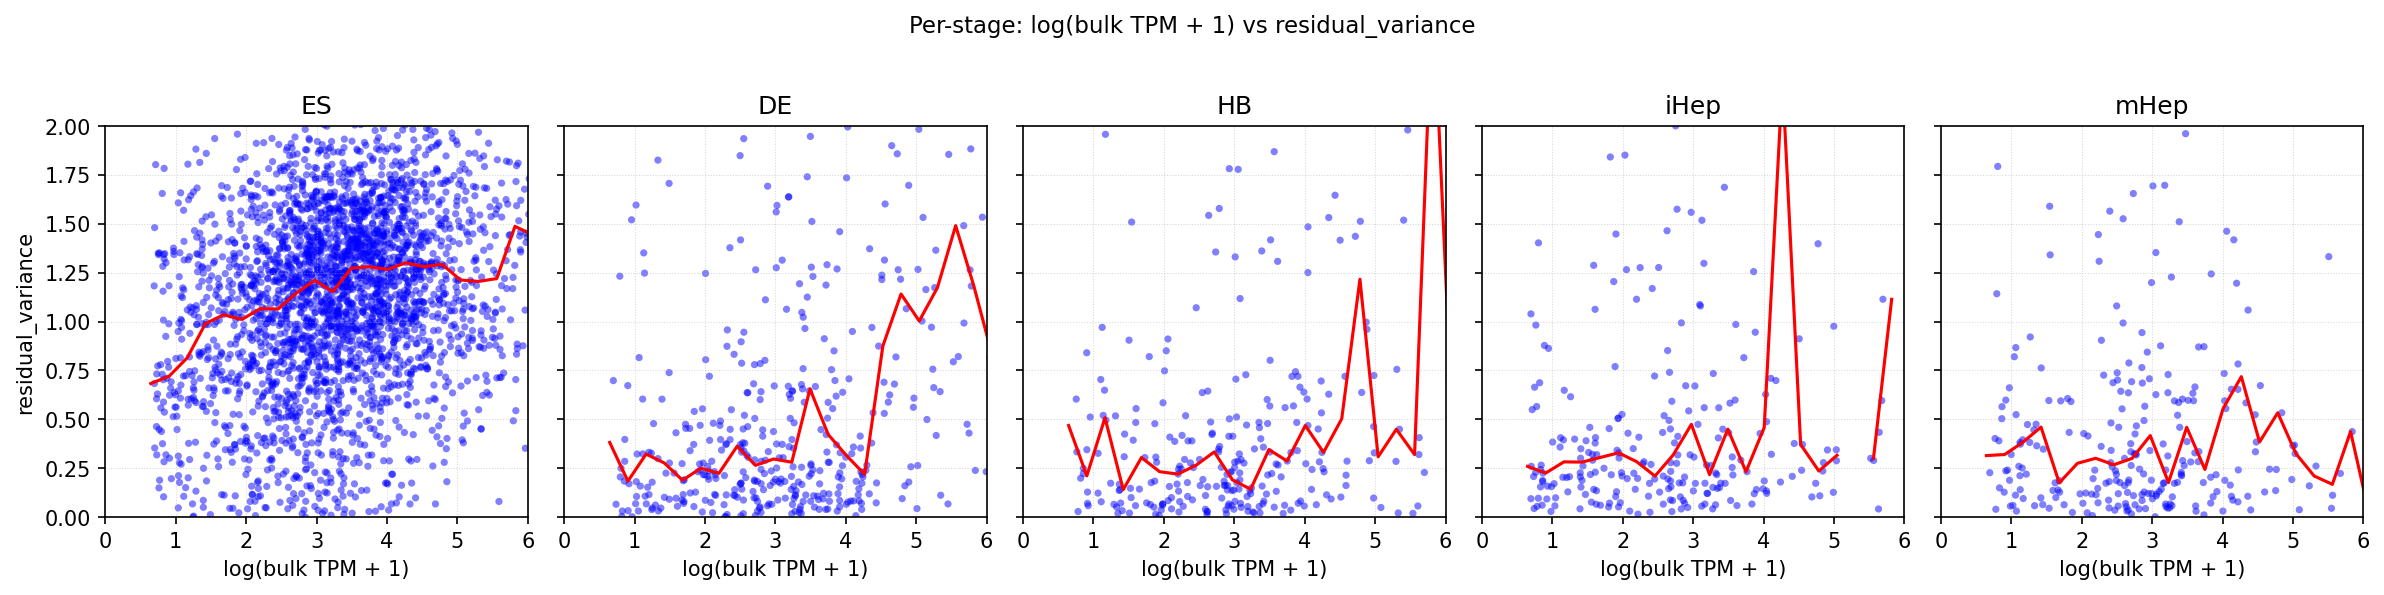

In [40]:
#residual variance VS bulk_tpm
fig, axes = plt.subplots(nrows=1, ncols=len(stages), figsize=(16, 4), dpi=150, sharey=True)

for i, stage in enumerate(stages):
    ax = axes[i]

    # --- Load and filter ---
    df = gene_bin_subcompartments[stage][
        ['Bin_ID', 'norm_rad', 'residual_variance', 'bulk_tpm', 'dropout_ratio']
    ].dropna().copy()

    # Filter out high-radial, high-expression outliers and dropout > 0.85
    tpm_threshold = df['bulk_tpm'].quantile(0.99)
    df_filtered = df[
        (df['bulk_tpm'] > 1) &
        ~((df['norm_rad'] > 0.8) & (df['bulk_tpm'] > tpm_threshold)) &
        (df['dropout_ratio'] < 0.85) 
    ].copy()

    # --- Compute X and Y ---
    df_filtered['log_bulk_tpm'] = np.log1p(df_filtered['bulk_tpm'])
    x = df_filtered['log_bulk_tpm'].to_numpy()
    y = df_filtered['residual_variance'].to_numpy()

    # --- Scatter: single color (blue) ---
    ax.scatter(
        x, y,
        s=12,
        alpha=0.5,
        color='blue',
        edgecolors='none'
    )

    # --- Compute median per x-bin ---
    bins = np.linspace(0, 7.5, 30)  # adjust bin number as needed
    df_filtered['x_bin'] = pd.cut(df_filtered['log_bulk_tpm'], bins)
    median_y = df_filtered.groupby('x_bin')['residual_variance'].median()
    bin_centers = [interval.mid for interval in median_y.index.categories]

    # --- Plot median line (red) ---
    ax.plot(bin_centers, median_y, color='red', linewidth=1.5)

    # --- Formatting ---
    ax.set_title(stage)
    ax.set_xlim(0, 6)
    ax.set_ylim(0, 2)
    ax.grid(True, linestyle=':', linewidth=0.5, alpha=0.5)

    ax.set_xlabel('log(bulk TPM + 1)')
    if i == 0:
        ax.set_ylabel('residual_variance')
    else:
        ax.set_ylabel("")

# Global adjustments
fig.suptitle('Per-stage: log(bulk TPM + 1) vs residual_variance', y=0.98, fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save & show
#outpath = "/home/xiangru.huo-umw/scHiC/scripts/plot2/fraction_resid_bulkTPM_0.02_median_dropout0.85_blue.pdf"
#plt.savefig(outpath, dpi=300)
plt.show()

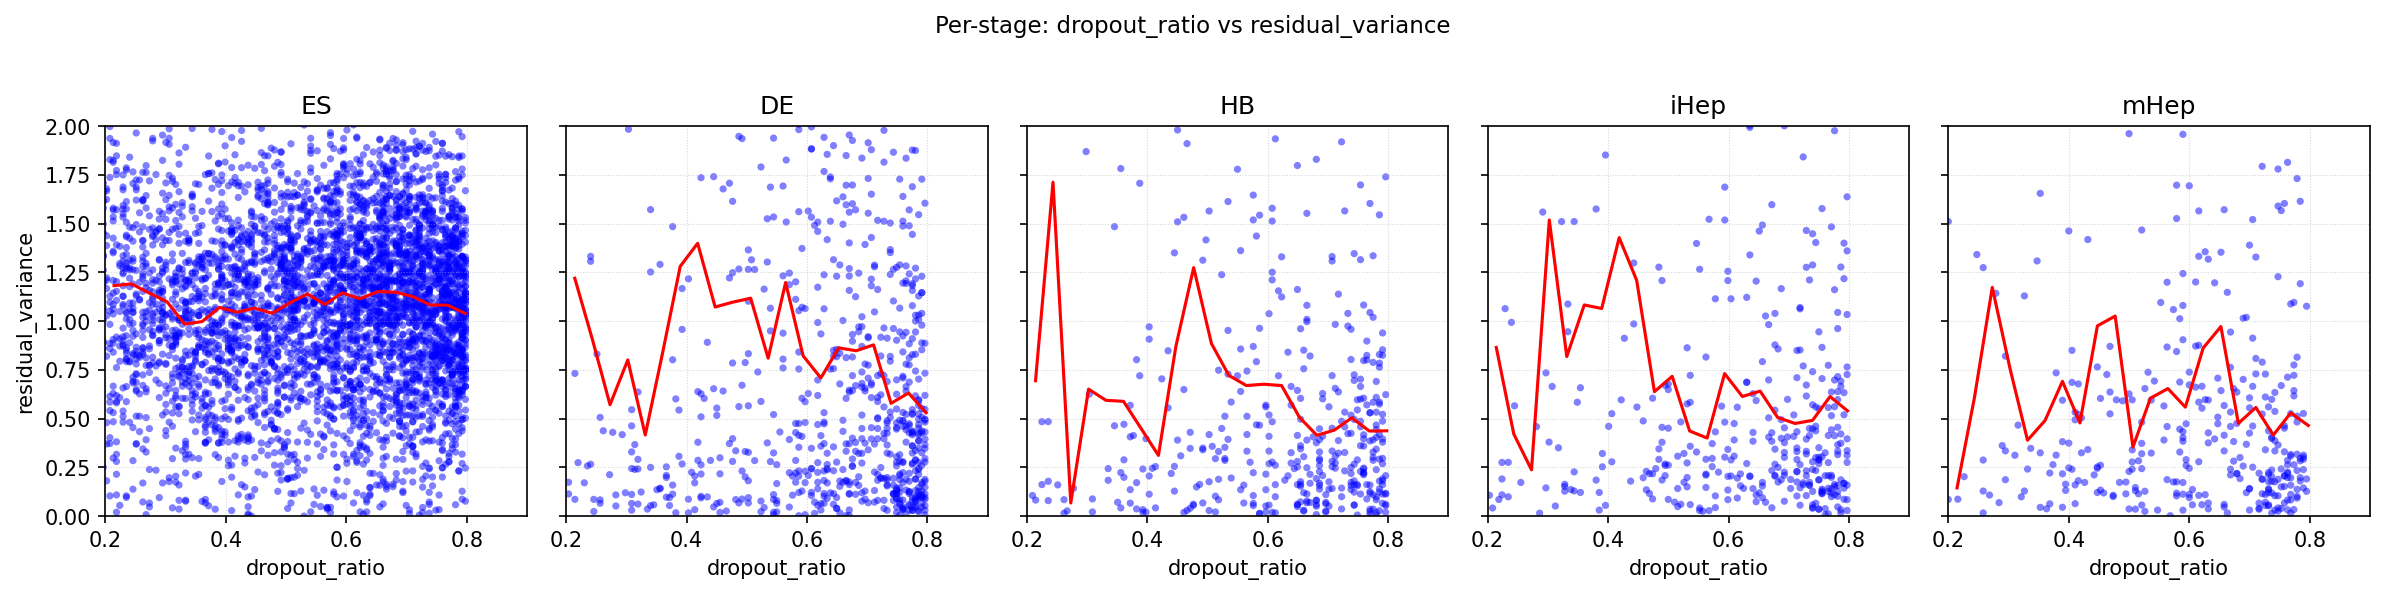

In [ ]:
#plot the dropout ratio VS residual variance
# stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']

fig, axes = plt.subplots(nrows=1, ncols=len(stages), figsize=(16, 4), dpi=150, sharey=True)

for i, stage in enumerate(stages):
    ax = axes[i]

    # --- Load and filter ---
    df = gene_bin_subcompartments[stage][
        ['Bin_ID', 'norm_rad', 'residual_variance', 'bulk_tpm', 'dropout_ratio']
    ].dropna().copy()

    # Filter out high-radial, high-expression outliers and restrict dropout range
    tpm_threshold = df['bulk_tpm'].quantile(0.99)
    df_filtered = df[
        (df['bulk_tpm'] > 1) &
        ~((df['norm_rad'] > 0.8) & (df['bulk_tpm'] > tpm_threshold)) &
        (df['dropout_ratio'] < 0.85) 
    ].copy()

    # --- X = dropout_ratio, Y = residual_variance ---
    x = df_filtered['dropout_ratio'].to_numpy()
    y = df_filtered['residual_variance'].to_numpy()

    # --- Scatter ---
    ax.scatter(
        x, y,
        s=12,
        alpha=0.5,
        color='blue',
        edgecolors='none'
    )

    # --- Compute median per dropout bin ---
    bins = np.linspace(0.2, 0.9, 25)  # bins across dropout range
    df_filtered['x_bin'] = pd.cut(df_filtered['dropout_ratio'], bins)
    median_y = df_filtered.groupby('x_bin')['residual_variance'].mean()
    bin_centers = [interval.mid for interval in median_y.index.categories]

    # --- Plot median line (red) ---
    ax.plot(bin_centers, median_y, color='red', linewidth=1.5)

    # --- Formatting ---
    ax.set_title(stage)
    ax.set_xlim(0.2, 0.9)
    ax.set_ylim(0, 2)
    ax.grid(True, linestyle=':', linewidth=0.5, alpha=0.5)

    ax.set_xlabel('dropout_ratio')
    if i == 0:
        ax.set_ylabel('residual_variance')
    else:
        ax.set_ylabel("")

# Global adjustments
fig.suptitle('Per-stage: dropout_ratio vs residual_variance', y=0.98, fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save & show
outpath = "/home/xiangru.huo-umw/scHiC/scripts/plot2/fraction_resid_dropout0.85_median_5stages.pdf"
plt.savefig(outpath, dpi=300)
plt.show()

In [39]:
#check how many genes left after filter expressionlevel and dropout_ratio
gene_counts_after_filtering = {}

tpm = 10
dropout_ratio = 0.85 #can try different threshold, like 1, 0.9,0.8, 0.7. I used 0.85 in finall filter


for i, stage in enumerate(stages):
    ax = axes[i]

    # Load and filter
    df = gene_bin_subcompartments[stage][[
        'Bin_ID', 'rad', 'residual_variance', 'bulk_tpm', 'trans_count_S.D._model', 'dropout_ratio'
    ]].dropna()
    
    # Compute 99th percentile TPM threshold
    tpm_threshold = df['bulk_tpm'].quantile(0.99)

    # Filter based on multiple conditions
    df_filtered = df[
        (df['bulk_tpm'] > tpm) &
        ~((df['rad'] > 4500) & (df['bulk_tpm'] > tpm_threshold)) &
        (df['dropout_ratio'] < dropout_ratio)
    ].copy()

    # Store gene count
    gene_counts_after_filtering[stage] = df_filtered.shape[0]

# Print results
for stage, count in gene_counts_after_filtering.items():
    print(f"{stage}: {count} genes(bulk_tpm>{tpm} and droupout < {dropout_ratio})")

ES: 2769 genes(bulk_tpm>10 and droupout < 0.85)
DE: 579 genes(bulk_tpm>10 and droupout < 0.85)
HB: 304 genes(bulk_tpm>10 and droupout < 0.85)
iHep: 238 genes(bulk_tpm>10 and droupout < 0.85)
mHep: 274 genes(bulk_tpm>10 and droupout < 0.85)


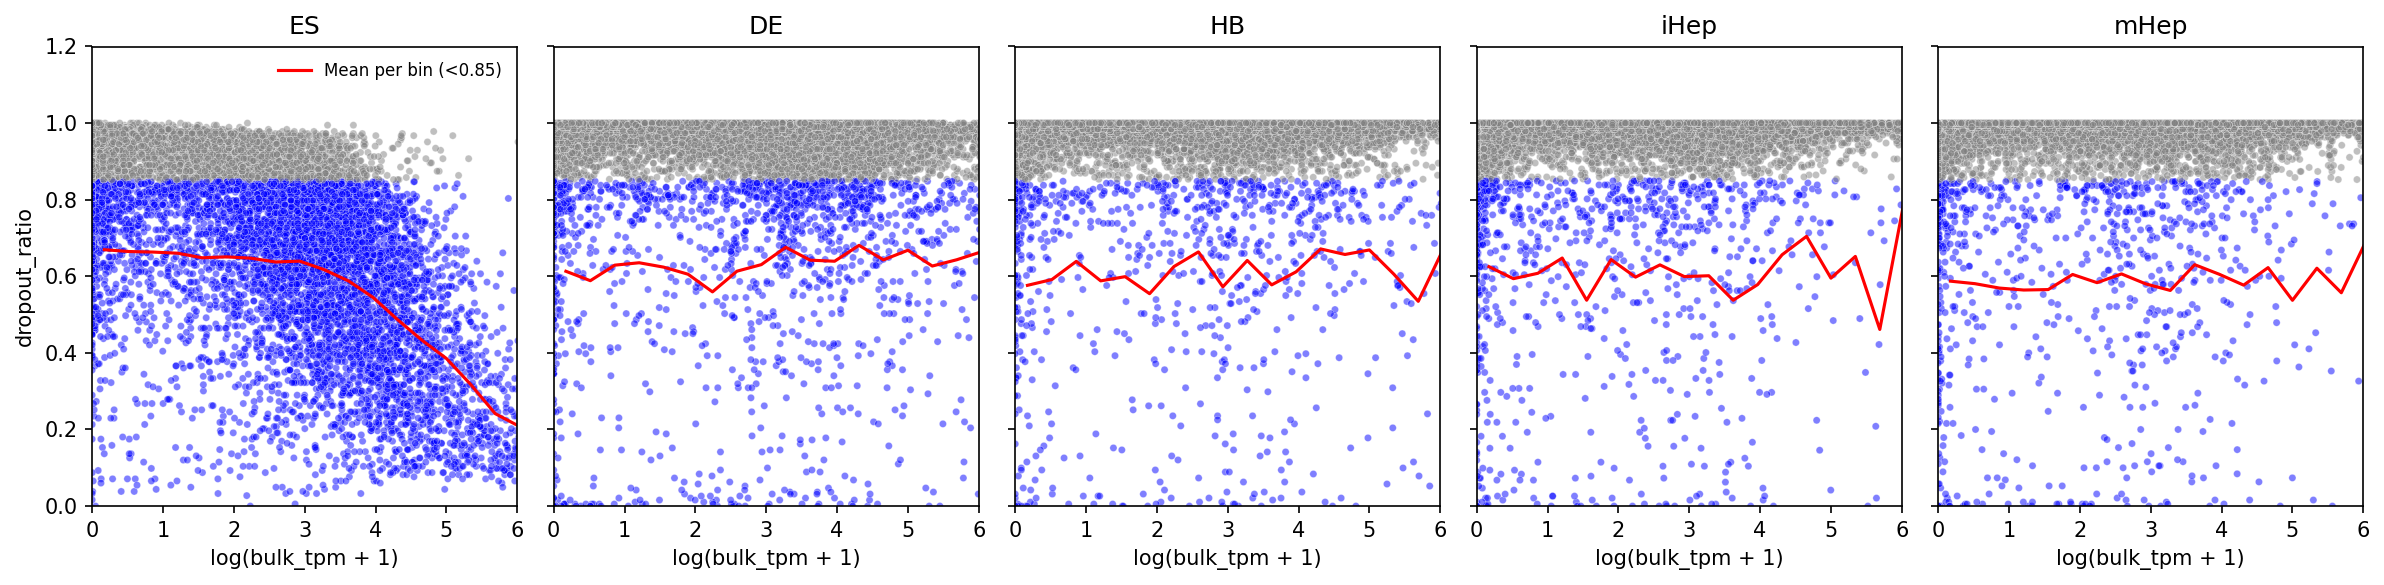

In [29]:
#plot the dropout ratio
fig, axes = plt.subplots(nrows=1, ncols=len(stages), figsize=(16, 4), dpi=150, sharey=True)

for i, stage in enumerate(stages):
    ax = axes[i]

    # === Prepare data ===
    df = gene_bin_subcompartments[stage][['bulk_tpm', 'dropout_ratio']].dropna().copy()
    df['log_bulk_tpm'] = np.log1p(df['bulk_tpm'])

    # Color grouping: dropout_ratio > 0.85 → grey, else → blue
    df['color_group'] = np.where(df['dropout_ratio'] > 0.85, 'high_dropout', 'normal')

    # --- Scatter plot ---
    sns.scatterplot(
        data=df,
        x='log_bulk_tpm',
        y='dropout_ratio',
        hue='color_group',
        palette={'high_dropout': 'grey', 'normal': 'blue'},
        alpha=0.5,
        s=12,
        ax=ax,
        legend=False
    )

    # === Compute mean curve for dropout_ratio < 0.85 ===
    df_filtered = df[df['dropout_ratio'] < 0.85].copy()
    bins = np.linspace(0, 10, 30)  # adjust bin number or range as needed
    df_filtered['x_bin'] = pd.cut(df_filtered['log_bulk_tpm'], bins)
    mean_y = df_filtered.groupby('x_bin')['dropout_ratio'].mean()
    bin_centers = [interval.mid for interval in mean_y.index.categories]

    # --- Plot mean line ---
    ax.plot(bin_centers, mean_y, color='red', linewidth=1.5, label='Mean per bin (<0.85)')

    # === Axis labels and limits ===
    ax.set_title(stage)
    ax.set_xlabel("log(bulk_tpm + 1)")
    if i == 0:
        ax.set_ylabel("dropout_ratio")
    else:
        ax.set_ylabel("")

    ax.set_xlim(0, 6)
    ax.set_ylim(0, 1.2)

    # Optional: show legend on the first subplot only
    if i == 0:
        ax.legend(frameon=False, loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/dropoutratio-VS-expression_with_meancurve_dropout0.85.pdf", dpi=300)
plt.show()

# Folding variability VS Expression variability

In [68]:
gene_bin_subcompartments[stage]

,vst.mean,vst.variance,vst.variance.expected,vst.variance.standardized,gene,stage_x,mean_expression,residual_variance,stage_y,Bin_ID,...,rgsd,icp,icpsd,transab,transabsd,tag,domain,entropy,cisratioCV_with_entropy,subcompartment
0,0.005714,0.005714,NaN,NaN,TSPAN6,mHep,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.000000,0.000000,0.000000,0.000000,TNMD,mHep,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.000000,0.000000,0.000000,0.000000,DPM1,mHep,0.0,0.001017,mHep,chr20_Bin50,...,54.433434,0.664678,0.150984,0.700501,0.207989,A2,domain,1.927815,0.314181,A2
3,0.000000,0.000000,0.000000,0.000000,SCYL3,mHep,0.0,0.000476,mHep,chr1_Bin169,...,56.050583,0.379025,0.234314,0.377438,0.301635,Quies,domain,1.461480,0.233261,Quies
4,0.000000,0.000000,0.000000,0.000000,C1orf112,mHep,0.0,0.000878,mHep,chr1_Bin169,...,60.165328,0.400150,0.249137,0.396437,0.304573,Quies,domain,1.632085,0.287920,Quies
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32245,0.011429,0.011363,NaN,NaN,KRTAP10-9,mHep,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A1
32246,0.017143,0.051429,0.019065,1.021162,AC112492.2,mHep,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
32247,0.011429,0.011363,NaN,NaN,AL034346.1,mHep,NaN,NaN,NaN,NaN,...,26.455909,0.561281,0.237243,0.544678,0.263502,B1,domain,2.000757,0.362001,B1
32248,0.005714,0.005714,NaN,NaN,SMCO4P1,mHep,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A1


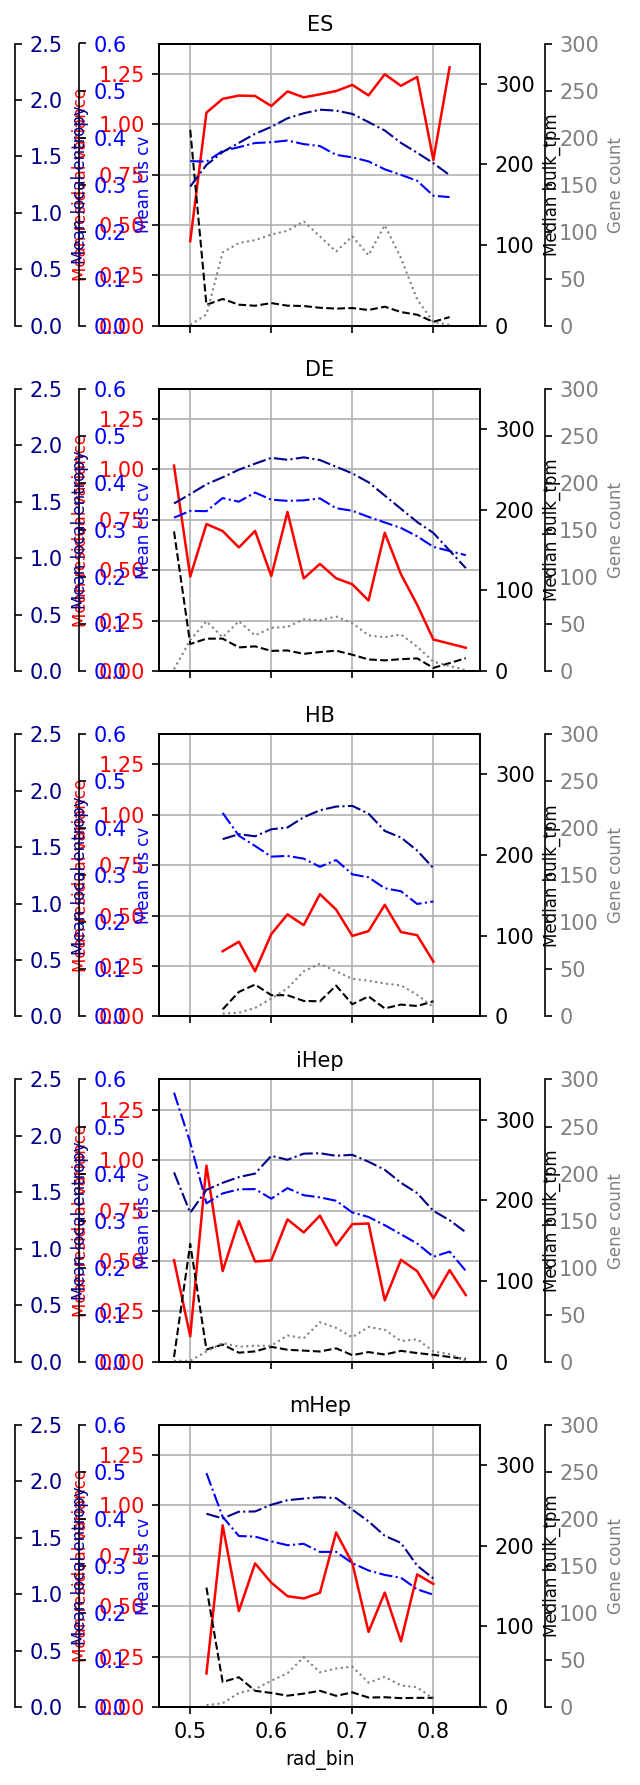

In [114]:
import matplotlib.pyplot as plt

stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(6, 12), dpi=150, sharex=True)

bin_size = 0.02
tpm = 1
dropout_ratio = 0.85

for i, stage in enumerate(stages):
    ax = axes[i]

    df = gene_bin_subcompartments[stage][[
        'Bin_ID', 'norm_rad', 'residual_variance', 'bulk_tpm',
        'cisratio_cv_model', 'dropout_ratio', 'entropy','cisratioCV_with_entropy'
    ]].dropna()
    
    tpm_threshold = df['bulk_tpm'].quantile(0.99)

    df_filtered = df[
        (df['bulk_tpm'] > tpm) &
        ~((df['norm_rad'] > 0.82) & (df['bulk_tpm'] > tpm_threshold)) &
        (df['dropout_ratio'] < dropout_ratio)
    ].copy()

    grouped = (
        df_filtered
        .groupby('Bin_ID')
        .agg({
            'norm_rad': 'mean',
            'residual_variance': 'mean',
            'bulk_tpm': 'median',
            'cisratioCV_with_entropy': 'mean',
            'entropy': 'mean'
        })
        .reset_index()
    )

    grouped['rad_bin_bin'] = (grouped['norm_rad'] / bin_size).astype(int) * bin_size

    stats_df = (
        grouped.groupby('rad_bin_bin')
        .agg(
            mean_resid_var=('residual_variance', 'mean'),
            median_bulk_tpm=('bulk_tpm', 'median'),
            gene_count=('Bin_ID', 'count'),
            mean_cis_cv=('cisratioCV_with_entropy', 'mean'),
            mean_entropy=('entropy', 'mean')
        )
        .reset_index()
    )

    stats_df = stats_df[stats_df['mean_resid_var'] <= 1.3]

    ax.plot(
        stats_df['rad_bin_bin'],
        stats_df['mean_resid_var'],
        color='red', lw=1.2,
        label='Mean residual variance'
    )
    ax.set_ylim(0, 1.4)
    ax.set_ylabel("Mean residual variance", fontsize=8, color='red')
    ax.tick_params(axis='y', labelcolor='red')
    ax.set_title(stage, fontsize=10)
    ax.grid(True, lw=0.8)

    ax2 = ax.twinx()
    ax2.plot(
        stats_df['rad_bin_bin'],
        stats_df['median_bulk_tpm'],
        color='black', lw=1, linestyle='--',
        label='Median bulk_tpm'
    )
    ax2.set_ylim(0, 350)
    ax2.set_ylabel("Median bulk_tpm", fontsize=8, color='black')
    ax2.tick_params(axis='y', labelcolor='black')

    ax3 = ax.twinx()
    ax3.spines["right"].set_position(("axes", 1.2))
    ax3.plot(
        stats_df['rad_bin_bin'],
        stats_df['gene_count'],
        color='grey', lw=1, linestyle=':',
        label='Gene count'
    )
    ax3.set_ylim(0, 300)
    ax3.set_ylabel("Gene count", fontsize=8, color='grey')
    ax3.tick_params(axis='y', labelcolor='grey')

    ax4 = ax.twinx()
    ax4.spines["right"].set_position(("axes", -0.25))
    ax4.plot(
        stats_df['rad_bin_bin'],
        stats_df['mean_cis_cv'],
        color='blue', lw=1, linestyle='-.',
        label='Mean cis cv'
    )
    ax4.set_ylim(0, 0.6)
    ax4.set_ylabel("Mean cis cv", fontsize=8, color='blue')
    ax4.tick_params(axis='y', labelcolor='blue')

    ax5 = ax.twinx()
    ax5.spines["right"].set_position(("axes", -0.45))
    ax5.plot(
        stats_df['rad_bin_bin'],
        stats_df['mean_entropy'],
        color='darkblue', lw=1, linestyle='-.',
        label='Mean local entropy'
    )
    ax5.set_ylim(0, 2.5)
    ax5.set_ylabel("Mean local entropy", fontsize=8, color='darkblue')
    ax5.tick_params(axis='y', labelcolor='darkblue')

    if i == 4:
        ax.set_xlabel("rad_bin", fontsize=9)

plt.tight_layout()
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/mean_resid_bulkTPM_geneCount_ciscv_entropy_vs_radbin_0.02_drop{dropout_ratio}_tpm{tpm}.pdf",     
            format="pdf",bbox_inches="tight" )
plt.show()

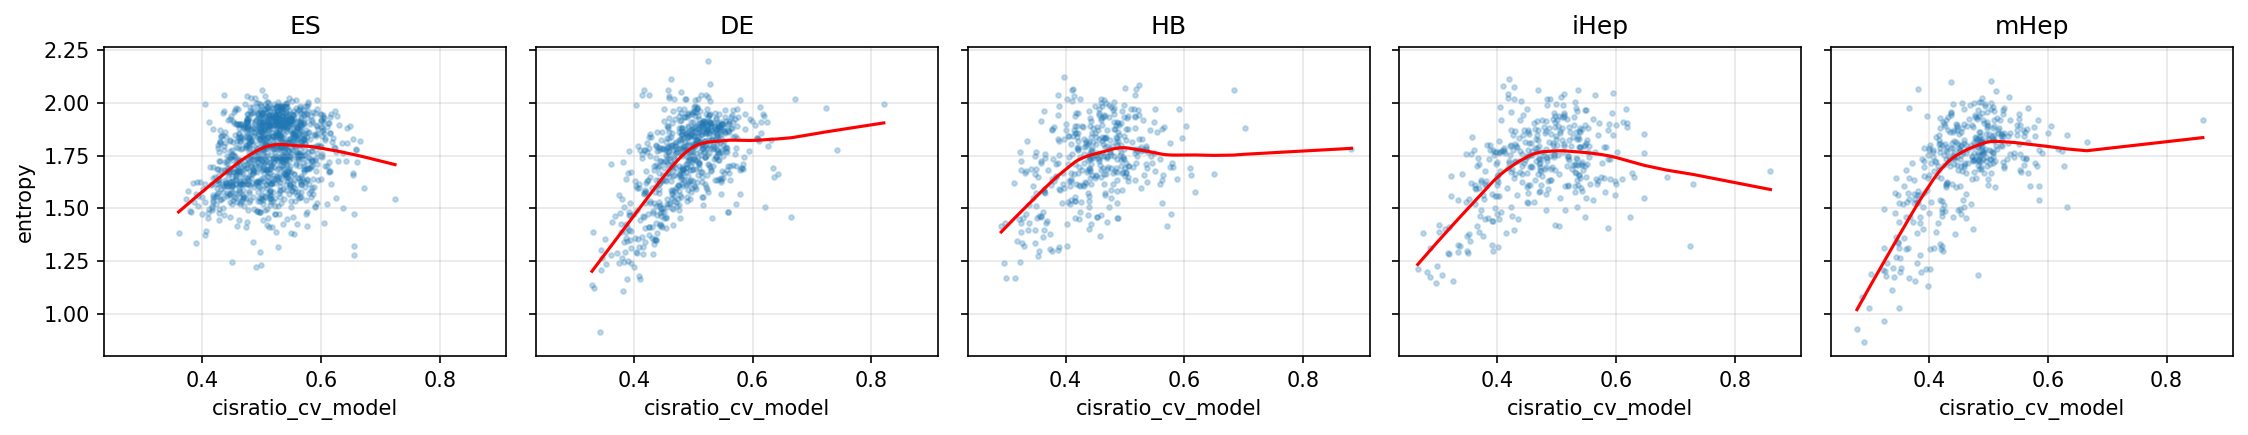

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns

stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']

fig, axes = plt.subplots(
    nrows=1,
    ncols=5,
    figsize=(15, 3),
    dpi=150,
    sharex=True,
    sharey=True
)

tpm = 1
dropout_ratio = 0.85

for i, stage in enumerate(stages):
    ax = axes[i]

    df = gene_bin_subcompartments[stage][[
        'Bin_ID',
        'bulk_tpm',
        'cisratio_cv_model',
        'dropout_ratio',
        'entropy'
    ]].dropna()

    df_filtered = df[
        (df['bulk_tpm'] > tpm) &
        (df['dropout_ratio'] < dropout_ratio)
    ].copy()

    grouped = (
        df_filtered
        .groupby('Bin_ID')
        .agg({
            'cisratio_cv_model': 'mean',
            'entropy': 'mean'
        })
        .reset_index()
    )

    sns.regplot(
        data=grouped,
        x='cisratio_cv_model',
        y='entropy',
        lowess=True,
        scatter_kws={'s': 5, 'alpha': 0.25},
        line_kws={'color': 'red', 'lw': 1.5},
        ax=ax
    )

    ax.set_title(stage)
    ax.set_xlabel('cisratio_cv_model')
    ax.set_ylabel('entropy' if i == 0 else '')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

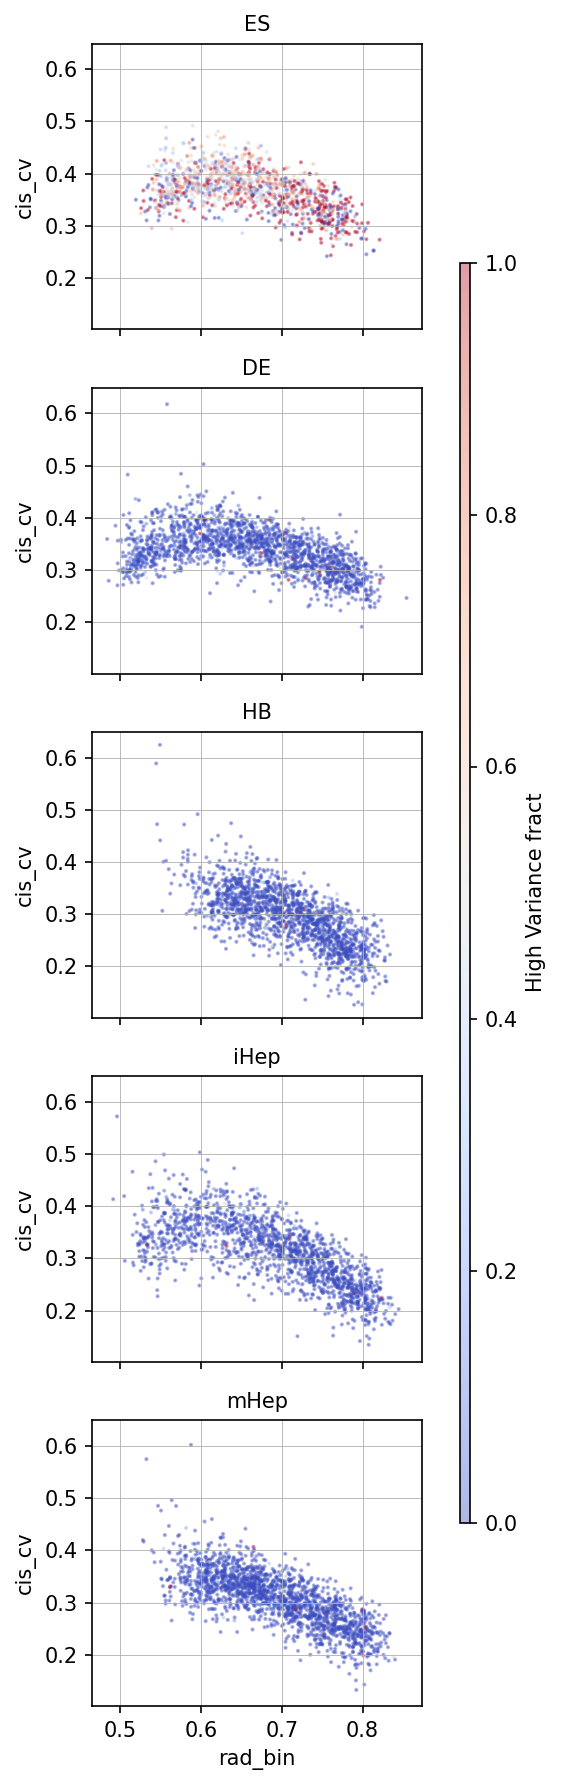

In [84]:
#colored by fraction of high_variable/low_variable genes in Bin
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(3.5, 12), dpi=150, sharex=True, sharey=True)

for i, stage in enumerate(stages):
    ax = axes[i]

    # Load and filter
    df = gene_bin_subcompartments[stage][[
        'Bin_ID', 'norm_rad', 'trans_count_S.D._model', 'cisratio_cv_model','residual_variance', 'bulk_tpm','cisratioCV_with_entropy'
    ]].dropna()

    df_filtered = df[df['bulk_tpm'] > 1].copy()

    # Group by Bin_ID
    grouped = df_filtered.groupby('Bin_ID').agg({
        'norm_rad': 'mean',
        'trans_count_S.D._model': 'mean',
        'cisratio_cv_model': 'mean',
        'residual_variance': 'mean',
        'bulk_tpm': 'mean',
        'cisratioCV_with_entropy':'mean'
    })

    # Calculate high_variance_fract & counts
    high_variance_fraction = df_filtered.groupby('Bin_ID')['residual_variance'].apply(lambda x: (x > 1).sum() / len(x))
    high_variance_counts = df_filtered.groupby('Bin_ID')['residual_variance'].apply(lambda x: (x > 1).sum())
    
    low_variance_fraction = df_filtered.groupby('Bin_ID')['residual_variance'].apply(lambda x: (x < 1).sum() / len(x))
    low_variance_counts = df_filtered.groupby('Bin_ID')['residual_variance'].apply(lambda x: (x < 1).sum()) 

    
    # Add it to grouped dataframe
    grouped['high_variance_fract'] = high_variance_fraction
    grouped['high_variance_counts'] = high_variance_counts  
    
#    grouped['low_variance_fract'] = low_variance_fraction
#    grouped['low_variance_counts'] = low_variance_counts  
                                                                                    
    # Reset index to keep Bin_ID as column
    grouped = grouped.reset_index()
    
    grouped['log_bulk_tpm'] = np.log1p(grouped['bulk_tpm'])

    # Plot all dots colored by high_variance_fract
    scatter = ax.scatter(
        grouped['norm_rad'],
        grouped['cisratioCV_with_entropy'],
#        c=grouped['low_variance_fract'],
        c=grouped['high_variance_fract'],
        cmap='coolwarm',
        s=1,
        alpha=0.4,
        vmin=0,
        vmax=1
    )

    ax.set_title(stage, fontsize=10)
    ax.grid(True, lw=0.4)
    if i == 4:
        ax.set_xlabel("rad_bin")
    ax.set_ylabel("cis_cv")

# Shared colorbar
fig.subplots_adjust(right=0.87)
cbar_ax = fig.add_axes([0.89, 0.15, 0.02, 0.7])
fig.colorbar(scatter, cax=cbar_ax, label='High Variance fract')

plt.tight_layout(rect=[0, 0, 0.86, 1])
#plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/rad_VS_cis_cv_colored_by_low_variance_fract.pdf")
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/rad_VS_cis_cv_colored_by_high_variance_fract.pdf")

plt.show()

# Trace gene expression level of high variable expressed genes during differentiation

In [ ]:
# Load TPM matrix with replicates and calculate p_value
from scipy.stats import ttest_ind

# --- Config ---
stage1, stage2 = 'ES', 'DE'
log2fc_threshold, pval_threshold = 1, 0.05
tpm_min = 1

# --- Load TPM matrix and calculate stats ---
tpm_df = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/bulkRNA_matrix/salmon.merged.gene_tpm.tsv", sep='\t').drop(columns=['gene_id'])
tpm_df.columns = ['gene', 'DE_rep1', 'DE_rep2', 'ES_rep1', 'ES_rep2', 'HB_rep1', 'HB_rep2', 'iHep_rep1', 'iHep_rep2', 'mHep_rep1', 'mHep_rep2']
rep_df = tpm_df[['gene', 'ES_rep1', 'ES_rep2', 'DE_rep1', 'DE_rep2']].set_index('gene').astype(float)

# Compute log2FC and p-values
stats = rep_df.apply(lambda row: pd.Series({
    'log2FC_bulk_tpm': np.log2((row[['DE_rep1', 'DE_rep2']].mean() + 1e-3) / (row[['ES_rep1', 'ES_rep2']].mean() + 1e-3)),
    'pval': ttest_ind(row[['DE_rep1', 'DE_rep2']], row[['ES_rep1', 'ES_rep2']], equal_var=False).pvalue
}), axis=1).reset_index()

stats['-log10_pval'] = -np.log10(stats['pval'])

# --- Load structure table and merge ---
columns = ['gene', 'residual_variance', 'bulk_tpm', 'Bin_ID', 'spd_bin', 'rad_bin', 'subcompartment', 'trans_count_S.D._model_bin', 'cisratio_cv']

df1 = gene_bin_subcompartments[stage1][columns].copy()
df2 = gene_bin_subcompartments[stage2][columns].copy()
df1 = df1.rename(columns={col: f"{col}_{stage1}" for col in columns if col != 'gene'})
df2 = df2.rename(columns={col: f"{col}_{stage2}" for col in columns if col != 'gene'})

merged = pd.merge(df1, df2, on='gene', how='inner')
merged = pd.merge(merged, stats, on='gene', how='inner')
#merged = merged[(merged[f'bulk_tpm_{stage1}'] > tpm_min) | (merged[f'bulk_tpm_{stage2}'] > tpm_min)]
merged = merged[(merged[f'bulk_tpm_{stage1}'] > tpm_min)]

# --- DEG Labeling ---
merged['DEG'] = 'n.s.'
merged.loc[(merged['log2FC_bulk_tpm'] > log2fc_threshold) & (merged['pval'] < pval_threshold), 'DEG'] = 'up'
merged.loc[(merged['log2FC_bulk_tpm'] < -log2fc_threshold) & (merged['pval'] < pval_threshold), 'DEG'] = 'down'
merged['basemean'] = 0.5 * (merged[f'bulk_tpm_{stage1}'] + merged[f'bulk_tpm_{stage2}'])
merged['log10_basemean'] = np.log10(merged['basemean'] + 1e-3)  # Add small value to avoid log(0)

In [ ]:
# STEP 3: Volcano Plot
plt.figure(figsize=(4, 4), dpi=150)

# Plot all background points (grey)
plt.scatter(
    merged['log2FC_bulk_tpm'],
    merged['-log10_pval'],
    c='lightgrey',
    s=0.5,
    alpha=0.5,
    label='All genes'
)

# Filter for points with residual_variance > 1
highlight = merged[merged[f'residual_variance_{stage1}'] > 1]

# Overlay only the high-residual-variance genes, colored by value
sc = plt.scatter(
    highlight['log2FC_bulk_tpm'],
    highlight['-log10_pval'],
    c=highlight[f'residual_variance_{stage1}'],
    cmap='coolwarm',
    vmin=0,
    vmax=2,
    s=0.5,
    alpha=0.5,
    label='residual_variance > 1'
)

# Threshold lines
plt.axhline(y=-np.log10(pval_threshold), color='black', linestyle='--', lw=1)
plt.axvline(x=log2fc_threshold, color='black', linestyle='--', lw=1)
plt.axvline(x=-log2fc_threshold, color='black', linestyle='--', lw=1)

# Labels
plt.xlabel(f"log2(FC) bulk_tpm ({stage2}/{stage1})")
plt.ylabel("-log10(p-value)")
plt.title(f"Volcano Plot: {stage1} vs {stage2} (residual_variance > 1 colored)")
plt.colorbar(sc, label=f"residual_variance ({stage1})")
plt.grid(True, lw=0.4)
plt.tight_layout()
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/volcano_log2FC_pval_{stage1}_vs_{stage2}_coloredbyResidualVar_gt1.pdf", format='pdf')
plt.show()

In [ ]:
# Plot volcano, colored by cistotal_cv model (ES stage) ---
plt.figure(figsize=(4, 4), dpi=150)

# Plot all background points (grey)
plt.scatter(
    merged['log2FC_bulk_tpm'],
    merged['-log10_pval'],
    c='lightgrey',
    s=0.5,
    alpha=0.5,
    label='All genes'
)


# Filter: Significant AND residual_variance > 1
highlight = merged[
    (merged['DEG'] != 'n.s.') & (merged[f'residual_variance_{stage1}'] > 1)
]

# Scatter plot for colored significant points
sc = plt.scatter(
    highlight['log2FC_bulk_tpm'],
    highlight['-log10_pval'],
    c=highlight[f'residual_variance_{stage1}'],
    cmap='coolwarm',
    vmin=0,
    vmax=2,
    s=1,
    alpha=0.5,
    label='sig (colored by residual_variance)'
)

# Threshold lines
plt.axhline(y=-np.log10(pval_threshold), color='black', linestyle='--', lw=1)
plt.axvline(x=log2fc_threshold, color='black', linestyle='--', lw=1)
plt.axvline(x=-log2fc_threshold, color='black', linestyle='--', lw=1)

# Labels
plt.xlabel(f'log2(FC) bulk_tpm ({stage2} / {stage1})')
plt.ylabel('-log10(p-value)')
plt.title(f'Volcano Plot (colored by residual_variance in {stage1})')
plt.colorbar(sc, label='residual_variance')
plt.grid(True, lw=0.4)
plt.tight_layout()

# --- Classification masks ---
sig_up = merged[(merged['log2FC_bulk_tpm'] > log2fc_threshold) & (merged['pval'] < pval_threshold)]
nonsig_up = merged[(merged['log2FC_bulk_tpm'] > log2fc_threshold) & (merged['pval'] >= pval_threshold)]
sig_down = merged[(merged['log2FC_bulk_tpm'] < -log2fc_threshold) & (merged['pval'] < pval_threshold)]
nonsig_down = merged[(merged['log2FC_bulk_tpm'] < -log2fc_threshold) & (merged['pval'] >= pval_threshold)]

# --- Residual variance > 1 subsets ---
rv_col = f'residual_variance_{stage1}'
sig_up_rv = sig_up[sig_up[rv_col] > 1]
nonsig_up_rv = nonsig_up[nonsig_up[rv_col] > 1]
sig_down_rv = sig_down[sig_down[rv_col] > 1]
nonsig_down_rv = nonsig_down[nonsig_down[rv_col] > 1]

# --- Calculate ratios ---
def calc_ratio(rv_group, total_group):
    return len(rv_group), len(total_group), (len(rv_group) / len(total_group)) if len(total_group) > 0 else 0

r1, t1, frac1 = calc_ratio(sig_up_rv, sig_up)
r2, t2, frac2 = calc_ratio(nonsig_up_rv, nonsig_up)
r3, t3, frac3 = calc_ratio(sig_down_rv, sig_down)
r4, t4, frac4 = calc_ratio(nonsig_down_rv, nonsig_down)

# --- Annotate on the plot ---
textprops = dict(fontsize=7, bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.5))

plt.text(
    0.97, 0.9, f"Sig Up\n{r1}/{t1} ({frac1:.1%})",
    transform=plt.gca().transAxes, ha='right', va='top', **textprops
)

plt.text(
    0.97, 0.05, f"Non-sig Up\n{r2}/{t2} ({frac2:.1%})",
    transform=plt.gca().transAxes, ha='right', va='bottom', **textprops
)

plt.text(
    0.03, 0.9, f"Sig Down\n{r3}/{t3} ({frac3:.1%})",
    transform=plt.gca().transAxes, ha='left', va='top', **textprops
)

plt.text(
    0.03, 0.05, f"Non-sig Down\n{r4}/{t4} ({frac4:.1%})",
    transform=plt.gca().transAxes, ha='left', va='bottom', **textprops
)

# Label total count of residual_variance > 1 genes
rv_count = len(merged[merged[f'residual_variance_{stage1}'] > 1])
plt.text(
    0.5, 0.94, f"Total residual_variance > 1 gene counts: {rv_count}",
    transform=plt.gca().transAxes,
    ha='center', va='bottom',
    fontsize=7,
    bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.5)
)

# Save to file
#plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/volcano_log2FC_pval_{stage1}_vs_{stage2}_coloredbyresidual_variance.pdf", format='pdf')
plt.show()

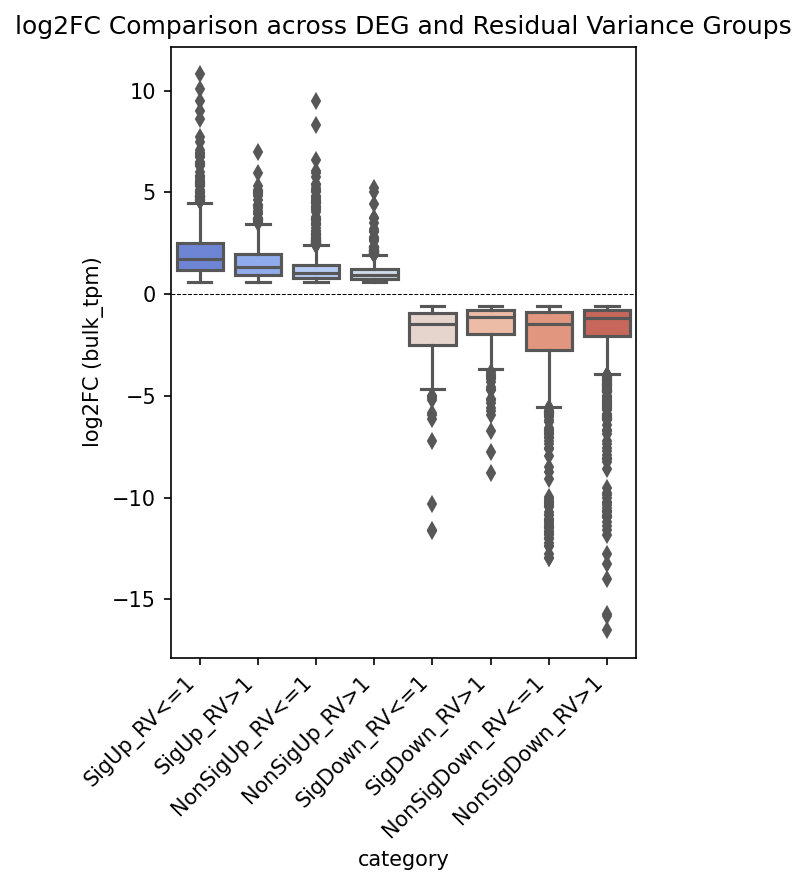

In [28]:
#compare the fold change
# --- Define category in correct order ---
ordered_categories = [
    'SigUp_RV<=1', 'SigUp_RV>1',
    'NonSigUp_RV<=1', 'NonSigUp_RV>1',
    'SigDown_RV<=1', 'SigDown_RV>1',
    'NonSigDown_RV<=1', 'NonSigDown_RV>1'
]

# --- Reclassify genes ---
def classify_gene(row):
    rv = row[rv_col] > 1
    fc = row['log2FC_bulk_tpm']
    sig = row['pval'] < pval_threshold

    if fc > log2fc_threshold and sig and not rv:
        return 'SigUp_RV<=1'
    elif fc > log2fc_threshold and sig and rv:
        return 'SigUp_RV>1'
    elif fc > log2fc_threshold and not sig and not rv:
        return 'NonSigUp_RV<=1'
    elif fc > log2fc_threshold and not sig and rv:
        return 'NonSigUp_RV>1'
    elif fc < -log2fc_threshold and sig and not rv:
        return 'SigDown_RV<=1'
    elif fc < -log2fc_threshold and sig and rv:
        return 'SigDown_RV>1'
    elif fc < -log2fc_threshold and not sig and not rv:
        return 'NonSigDown_RV<=1'
    elif fc < -log2fc_threshold and not sig and rv:
        return 'NonSigDown_RV>1'
    else:
        return 'Other'

# Apply classification
merged['category'] = merged.apply(classify_gene, axis=1)

# Filter for the 8 relevant groups
filtered = merged[merged['category'].isin(ordered_categories)]
filtered['category'] = pd.Categorical(filtered['category'], categories=ordered_categories, ordered=True)

# --- Plot ---
plt.figure(figsize=(4, 6), dpi=150)
sns.boxplot(
    data=filtered,
    x='category',
    y='log2FC_bulk_tpm',
    palette='coolwarm'
)
plt.axhline(0, color='black', lw=0.5, linestyle='--')
plt.ylabel('log2FC (bulk_tpm)')
plt.title('log2FC Comparison across DEG and Residual Variance Groups')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

# Optional save
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/log2FC_comparison_betweenRV<1and>1.pdf", format='pdf')
plt.show()

# GO analysis

In [2]:
#check the developmental but nonvariable gene in GO term, where area they localized.
# === Path to your GO results ===
go_path = "/home/xiangru.huo-umw/scHiC/scripts/inter_file/top15_GO_terms_4groups.tsv"

# === Load GO term table ===
go_df = pd.read_csv(go_path, sep="\t")

# === Define your 4 groups ===
ordered_groups = ['Up_RV>1', 'Up_RV<=1', 'Down_RV>1', 'Down_RV<=1']

# === Helper function: extract all unique genes from the "intersections" column ===
def extract_genes(series):
    genes = set()
    for val in series.dropna():
        for g in str(val).replace(" ", "").split(","):
            if g:
                genes.add(g)
    return sorted(genes)

# === Build dictionary of enriched genes per group ===
group_genes_enriched = {}
for grp in ordered_groups:
    subset = go_df[go_df["Group"] == grp]
    group_genes_enriched[grp] = extract_genes(subset["intersections"])
    print(f"✅ {grp}: {len(group_genes_enriched[grp])} enriched genes found")
    


✅ Up_RV>1: 0 enriched genes found
✅ Up_RV<=1: 507 enriched genes found
✅ Down_RV>1: 59 enriched genes found
✅ Down_RV<=1: 355 enriched genes found


In [7]:
group_genes_enriched[grp]

["'ABCG2'",
 "'ACTA2'",
 "'ACTN3'",
 "'ADA'",
 "'ADAM15'",
 "'ADAM22'",
 "'ADAMTS16'",
 "'ADCYAP1R1'",
 "'ADD2'",
 "'ADORA2B'",
 "'ADRA2A'",
 "'AGAP2'",
 "'AIF1'",
 "'AKAP5'",
 "'ALDH7A1'",
 "'ALOX5'",
 "'ALPL'",
 "'AMBP'",
 "'AMPH'",
 "'ANXA9'",
 "'APLP1'",
 "'AR'",
 "'ARC'",
 "'ARC']",
 "'ARRB2'",
 "'ARRDC4'",
 "'ASS1'",
 "'ASTL'",
 "'ASTN1'",
 "'ATP1A3'",
 "'ATP2A3'",
 "'ATP2C2'",
 "'ATP6V0A4'",
 "'BCAM'",
 "'BCHE'",
 "'BCL6'",
 "'BDNF'",
 "'BMP6'",
 "'BOC'",
 "'BTN3A1'",
 "'BTN3A2'",
 "'C1QL1'",
 "'CA7'",
 "'CACNA1F'",
 "'CACNA1G'",
 "'CACNG7'",
 "'CADM3'",
 "'CADPS2'",
 "'CALB2'",
 "'CALCB'",
 "'CATSPER4'",
 "'CBLN1'",
 "'CCBE1'",
 "'CCND1'",
 "'CD4'",
 "'CD74'",
 "'CD9'",
 "'CDH1'",
 "'CDH23'",
 "'CDH4'",
 "'CDH9'",
 "'CDHR1'",
 "'CDKN1A'",
 "'CGREF1'",
 "'CHGA'",
 "'CHRDL1'",
 "'CHRM3'",
 "'CHRNA4'",
 "'CHRNA9'",
 "'CHRNB2'",
 "'CHRNB4'",
 "'CHST2'",
 "'CHST4'",
 "'COL5A3'",
 "'COL6A3'",
 "'COL8A2'",
 "'CORO1A'",
 "'CPT1A'",
 "'CRB2'",
 "'CRYBB1'",
 "'CSPG5'",
 "'CST1'",
 "'CTNN

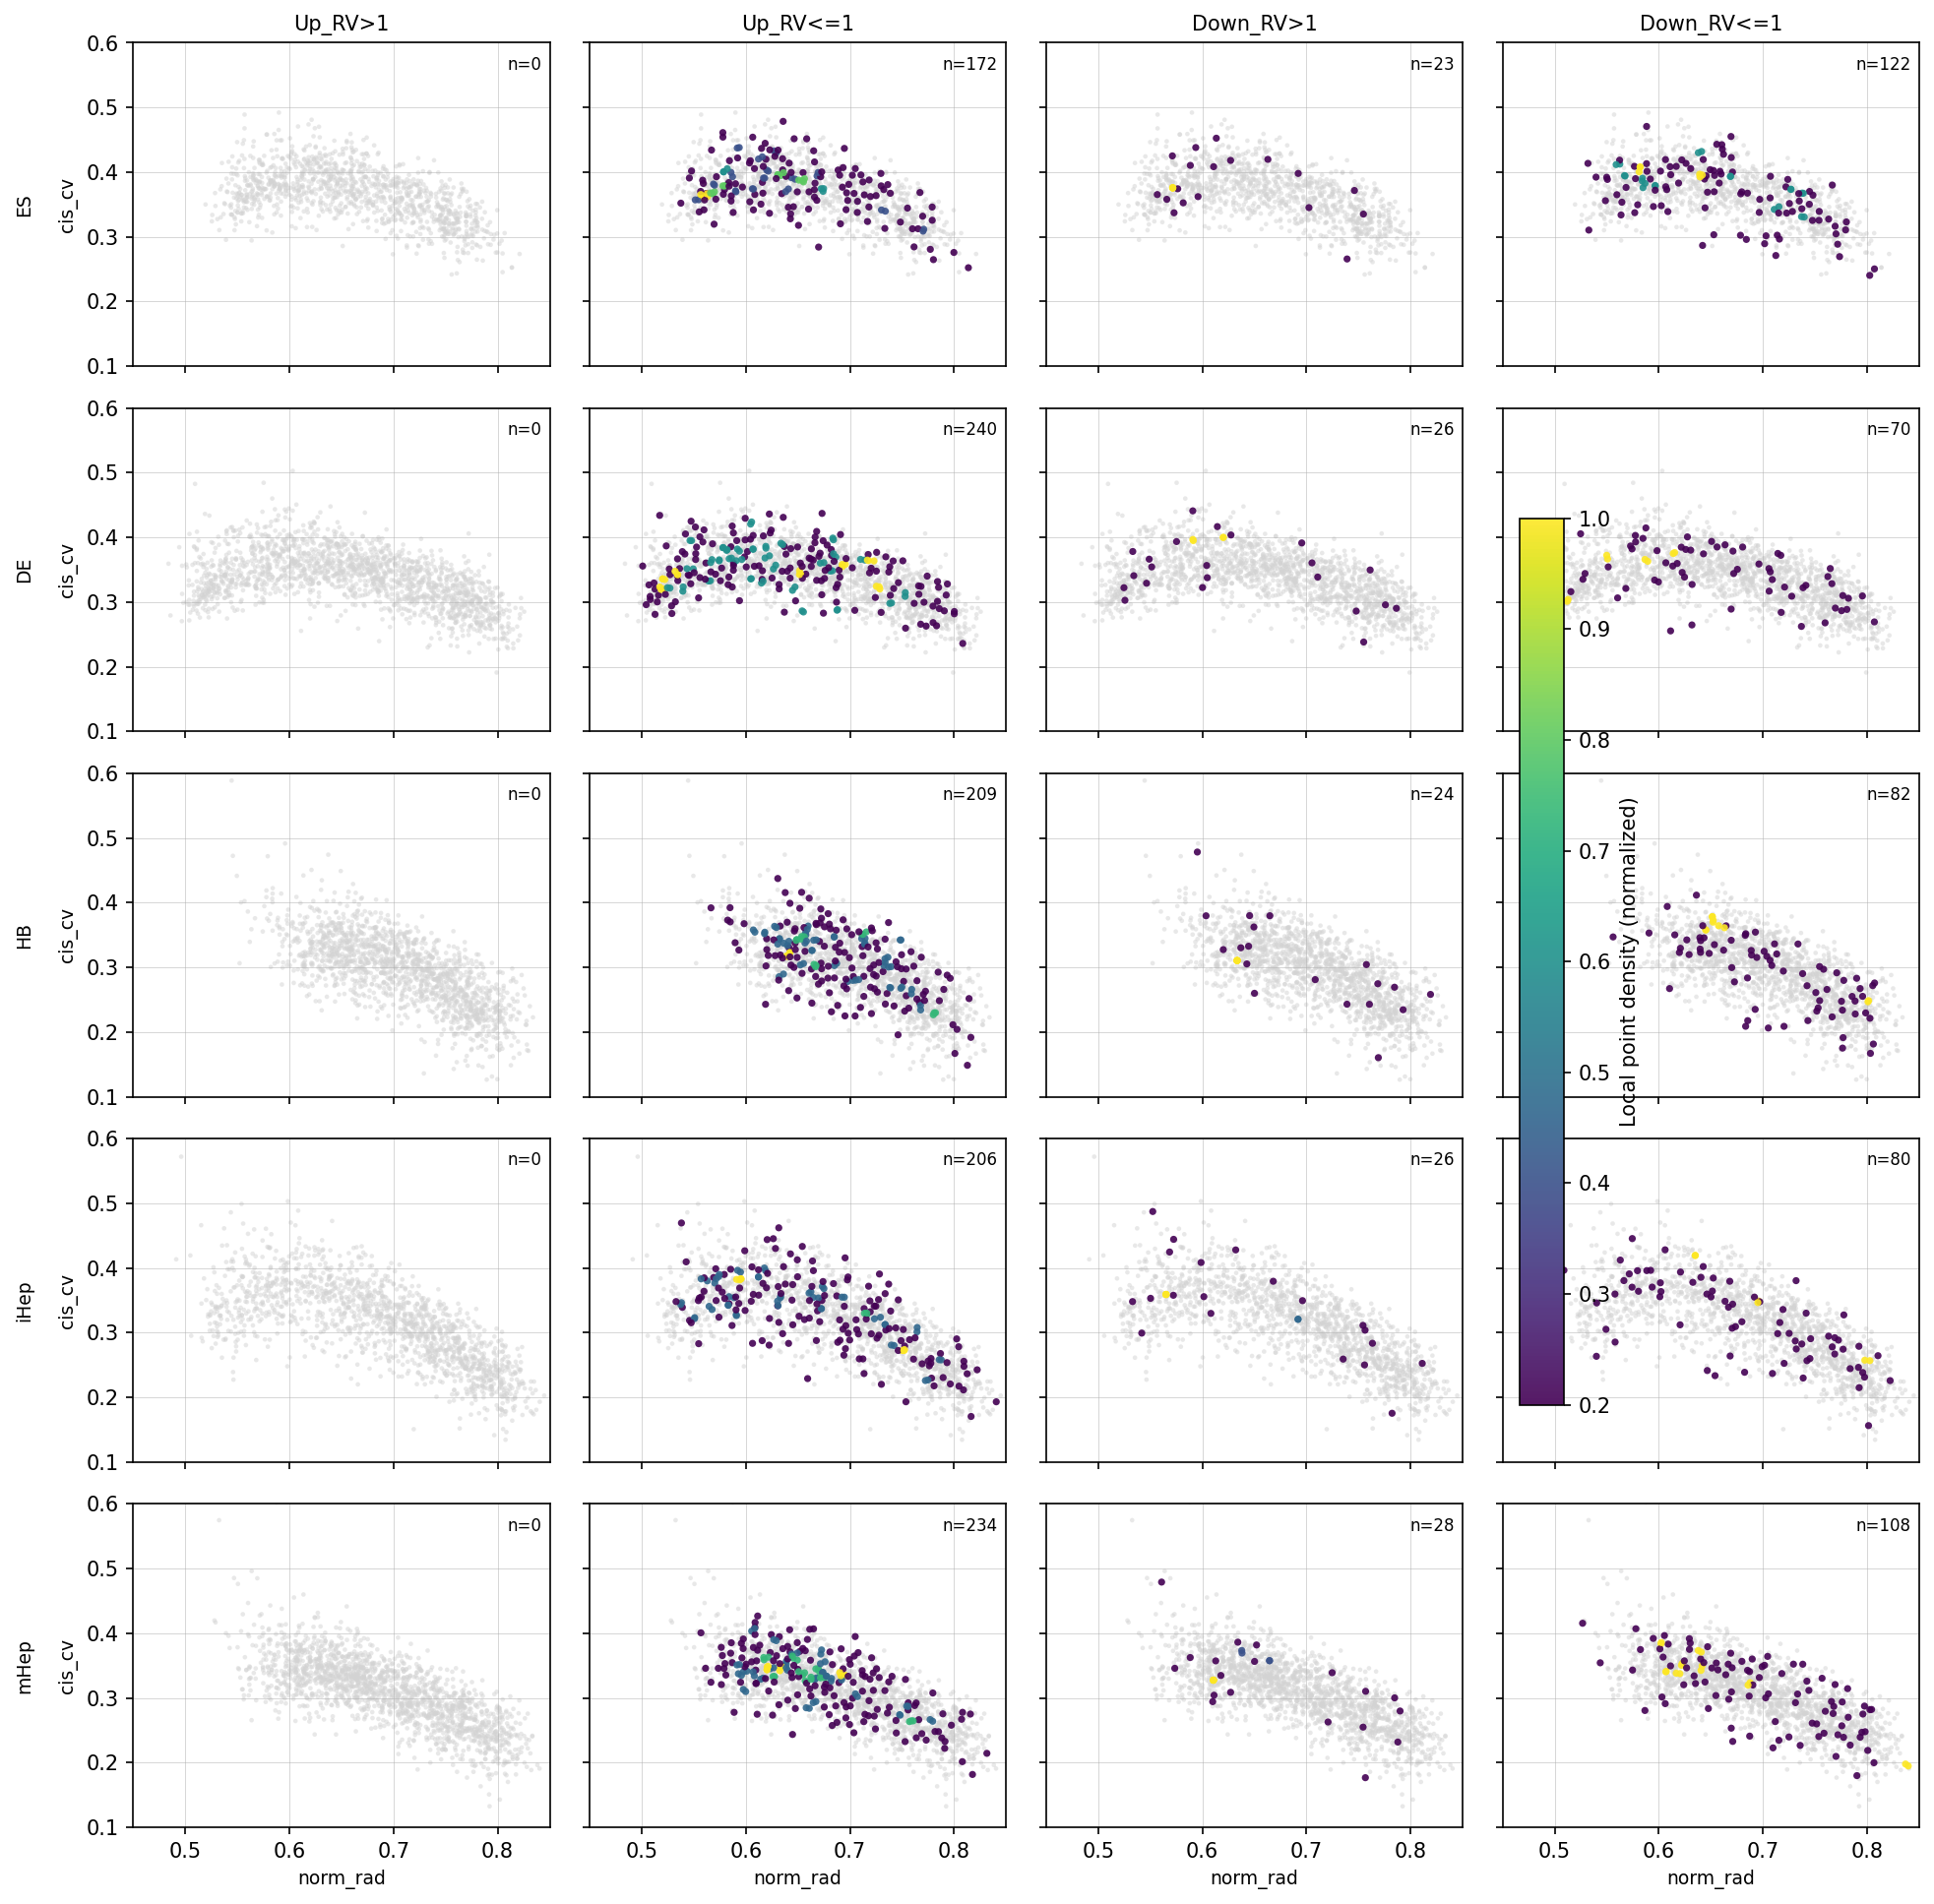

In [30]:
#color the GO term genes on Radial dist VS folding variability scatter plot
ordered_groups = ['Up_RV>1', 'Up_RV<=1', 'Down_RV>1', 'Down_RV<=1']

# === Plot settings ===
stages = ['ES', 'DE', 'HB', 'iHep', 'mHep']
group_colors = {
    'Up_RV>1':   'crimson',
    'Up_RV<=1':  'orange',
    'Down_RV>1': 'royalblue',
    'Down_RV<=1':'teal'
}
xlim = (0.45, 0.85)
ylim = (0.1, 0.6)
min_tpm = 1  # filter

# === Helpers to normalize gene symbols ===
def _clean_symbol(s):
    if s is None:
        return ""
    s = str(s).strip()
    s = s.strip("'\"").strip()   # remove extra quotes
    return s.upper()             # unify case

def normalize_gene_set(iterable):
    out = set()
    for x in (iterable or []):
        sx = _clean_symbol(x)
        if sx and sx.lower() not in {"nan", "none"}:
            out.add(sx)
    return out

# --- Density helper: 2D histogram per panel ---
def point_density(x, y, bins=(60, 60), xlim=None, ylim=None):
    """
    Approximate local density for each (x,y) using 2D histogram counts.
    Returns an array in [0,1] (normalized by max count).
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if x.size == 0:
        return np.array([])
    # Use current axes limits or provided ranges for consistent binning
    xr = xlim if xlim is not None else (np.nanmin(x), np.nanmax(x))
    yr = ylim if ylim is not None else (np.nanmin(y), np.nanmax(y))
    # Compute 2D histogram
    H, xe, ye = np.histogram2d(x, y, bins=bins, range=[xr, yr])
    # Map each point to its bin
    xi = np.clip(np.digitize(x, xe) - 1, 0, H.shape[0]-1)
    yi = np.clip(np.digitize(y, ye) - 1, 0, H.shape[1]-1)
    d = H[xi, yi].astype(float)
    m = d.max()
    if m > 0:
        d /= m
    return d

# === Clean the group -> gene mapping ===
group_genes_enriched_clean = {
    grp: normalize_gene_set(group_genes_enriched.get(grp, []))
    for grp in ordered_groups
}

# === Build subplot grid: rows = stages, cols = 4 groups ===
n_rows = len(stages)
n_cols = len(ordered_groups)
fig_w = 3.3 * n_cols
fig_h = 2.6 * n_rows
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(fig_w, fig_h), dpi=150, sharex=True, sharey=True)

# In case matplotlib gives a 1D axes array for a single row/col
if n_rows == 1:
    axes = np.array([axes])
if n_cols == 1:
    axes = axes[:, np.newaxis]

# We'll capture one ScalarMappable for a single shared colorbar later
cbar_mappable = None

for i, stage in enumerate(stages):
    # --- Pull and clean per-stage data ---
    cols = ['gene', 'Bin_ID', 'norm_rad', 'cisratioCV_with_entropy', 'trans_count_S.D._model', 'bulk_tpm']
    available_cols = [c for c in cols if c in gene_bin_subcompartments[stage].columns]
    df = gene_bin_subcompartments[stage][available_cols].copy()

    # Required
    required = ['gene', 'Bin_ID', 'norm_rad', 'cisratioCV_with_entropy']
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(f"Missing required columns for stage '{stage}': {missing}")

    df = df.dropna(subset=required)
    if 'bulk_tpm' in df.columns:
        df = df[df['bulk_tpm'] > min_tpm].copy()

    df['gene_norm'] = df['gene'].apply(_clean_symbol)

    # Background (Bin-level means) once per stage
    grouped = (
        df.groupby('Bin_ID', as_index=False)
          .agg(norm_rad=('norm_rad', 'mean'),
               cisratio_cv_model=('cisratioCV_with_entropy', 'mean'))
    )

    for j, grp in enumerate(ordered_groups):
        ax = axes[i, j]

        # Background in light gray
        ax.scatter(
            grouped['norm_rad'],
            grouped['cisratio_cv_model'],
            color='lightgray',
            s=5,
            alpha=0.5,
            edgecolor='none',
            zorder=1
        )

        # Foreground: this group's genes
        genes = group_genes_enriched_clean.get(grp, set())
        sub = df[df['gene_norm'].isin(genes)] if genes else df.iloc[0:0]  # empty if no genes
        n_sub = len(sub)

        if n_sub:
            # Compute local density per point within fixed axes limits
            dens = point_density(
                sub['norm_rad'].values,
                sub['cisratioCV_with_entropy'].values,
                bins=(60, 60),
                xlim=xlim,
                ylim=ylim
            )

            sc = ax.scatter(
                sub['norm_rad'],
                sub['cisratioCV_with_entropy'],
                c=dens,                 # color by density (0..1)
                cmap='viridis',         # choose any colormap you like
                s=12,
                alpha=0.9,
                edgecolor='none',
                zorder=2
            )

            # Save one mappable for a shared colorbar
            if cbar_mappable is None:
                cbar_mappable = sc

        # Styling per-panel
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.grid(True, lw=0.4, alpha=0.6)

        # Row labels (stage) on first column only
        if j == 0:
            ax.set_ylabel(f"{stage}\n\ncis_cv", fontsize=9)
        else:
            ax.set_ylabel("")

        # Column headers (group) on top row only
        if i == 0:
            ax.set_title(f"{grp}", fontsize=10)

        # Only bottom row gets x label
        if i == n_rows - 1:
            ax.set_xlabel("norm_rad", fontsize=9)
        else:
            ax.set_xlabel("")

        # Small count annotation in the top-right of each panel
        ax.text(0.98, 0.96, f"n={n_sub}", transform=ax.transAxes,
                ha='right', va='top', fontsize=8, color='black')

# Add a single shared colorbar (if we plotted any foreground points)
if cbar_mappable is not None:
    cbar = fig.colorbar(cbar_mappable, ax=axes.ravel().tolist(), shrink=0.6, pad=0.01)
    cbar.set_label("Local point density (normalized)", rotation=90)

plt.tight_layout()
#plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/rad_vs_ciscv_overlay_GOenriched_groups_4cols_density.pdf")
plt.show()

In [31]:
# save the gene list
cbar_mappable = None

# Save the exact foreground data used for plotting
plot_used_dfs = []

for i, stage in enumerate(stages):

    # --- Pull and clean per-stage data ---
    cols = ['gene', 'Bin_ID', 'norm_rad', 'cisratioCV_with_entropy',
            'trans_count_S.D._model', 'bulk_tpm']
    available_cols = [c for c in cols if c in gene_bin_subcompartments[stage].columns]
    df = gene_bin_subcompartments[stage][available_cols].copy()

    # Required columns
    required = ['gene', 'Bin_ID', 'norm_rad', 'cisratioCV_with_entropy']
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(f"Missing required columns for stage '{stage}': {missing}")

    df = df.dropna(subset=required)

    if 'bulk_tpm' in df.columns:
        df = df[df['bulk_tpm'] > min_tpm].copy()

    df['gene_norm'] = df['gene'].apply(_clean_symbol)

    # Background (one point per bin)
    grouped = (
        df.groupby('Bin_ID', as_index=False)
          .agg(
              norm_rad=('norm_rad', 'mean'),
              cisratio_cv_model=('cisratioCV_with_entropy', 'mean')
          )
    )

    for j, grp in enumerate(ordered_groups):

        ax = axes[i, j]

        # -----------------------------
        # Background (gray)
        # -----------------------------
        ax.scatter(
            grouped['norm_rad'],
            grouped['cisratio_cv_model'],
            color='lightgray',
            s=5,
            alpha=0.5,
            edgecolor='none',
            zorder=1
        )

        # -----------------------------
        # Foreground (GO genes)
        # -----------------------------
        genes = group_genes_enriched_clean.get(grp, set())
        sub = df[df['gene_norm'].isin(genes)] if genes else df.iloc[0:0]

        n_sub = len(sub)

        # Save the exact dataframe used for plotting
        sub_save = sub.copy()
        sub_save["stage"] = stage
        sub_save["GO_group"] = grp
        sub_save["n_genes_in_panel"] = n_sub
        plot_used_dfs.append(sub_save)

        if n_sub:

            dens = point_density(
                sub['norm_rad'].values,
                sub['cisratioCV_with_entropy'].values,
                bins=(60, 60),
                xlim=xlim,
                ylim=ylim
            )

            sc = ax.scatter(
                sub['norm_rad'],
                sub['cisratioCV_with_entropy'],
                c=dens,
                cmap='viridis',
                s=12,
                alpha=0.9,
                edgecolor='none',
                zorder=2
            )

            if cbar_mappable is None:
                cbar_mappable = sc

        # -----------------------------
        # Styling
        # -----------------------------
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.grid(True, lw=0.4, alpha=0.6)

        if j == 0:
            ax.set_ylabel(f"{stage}\n\ncis_cv", fontsize=9)
        else:
            ax.set_ylabel("")

        if i == 0:
            ax.set_title(grp, fontsize=10)

        if i == n_rows - 1:
            ax.set_xlabel("norm_rad", fontsize=9)
        else:
            ax.set_xlabel("")

        ax.text(
            0.98, 0.96,
            f"n={n_sub}",
            transform=ax.transAxes,
            ha='right',
            va='top',
            fontsize=8,
            color='black'
        )

# -----------------------------
# Save plotted dataframe
# -----------------------------
plot_used_df = pd.concat(plot_used_dfs, ignore_index=True)

save_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/rad_vs_ciscv_GOenriched_groups_plot_used_dataframe.tsv"

plot_used_df.to_csv(save_path, sep="\t", index=False)

print(f"Saved dataframe to:\n{save_path}")
print(f"Total plotted rows: {len(plot_used_df)}")

# -----------------------------
# Shared colorbar
# -----------------------------
if cbar_mappable is not None:
    cbar = fig.colorbar(
        cbar_mappable,
        ax=axes.ravel().tolist(),
        shrink=0.6,
        pad=0.01
    )
    cbar.set_label("Local point density (normalized)", rotation=90)

Saved dataframe to:
/home/xiangru.huo-umw/scHiC/scripts/plot2/rad_vs_ciscv_GOenriched_groups_plot_used_dataframe.tsv
Total plotted rows: 1650


In [7]:
#load file
file = "/home/xiangru.huo-umw/scHiC/scripts/plot2/rad_vs_ciscv_GOenriched_groups_plot_used_dataframe.tsv"

plot_used_df = pd.read_csv(file, sep = '\t')

In [5]:
#load gene locale information
file = "/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/dominant_locale_per_gene_5stages_inclSpeckleNucleoli.csv"

gene_locale = pd.read_csv(file)

In [9]:
#check their locale 
# ----------------------------
# Prepare ES genes and merge locale table
# ----------------------------
df = plot_used_df[plot_used_df["stage"] == "ES"].copy()

df = df.merge(
    gene_locale,
    on="gene",
    how="left"
)

df["gene_norm"] = (
    df["gene"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# remove duplicate gene per GO_group
df = df.drop_duplicates(subset=["gene_norm", "GO_group"])

# ----------------------------
# Settings
# ----------------------------
go_order = ["Down_RV<=1", "Down_RV>1", "Up_RV<=1"]

locale_cols = ["dom_h1", "dom_DE", "dom_HB", "dom_iHEP", "dom_mHEP"]

locale_order = ["NL-act", "NL-rep", "env", "spe", "Nucleolus"]

locale_colors = {
    "NL-act": "#8e63c7",
    "NL-rep": "#e41a1c",
    "env": "#377eb8",
    "spe": "#ff7f00",
    "Nucleolus": "#4daf4a"
}

# keep only selected GO groups
df = df[df["GO_group"].isin(go_order)].copy()

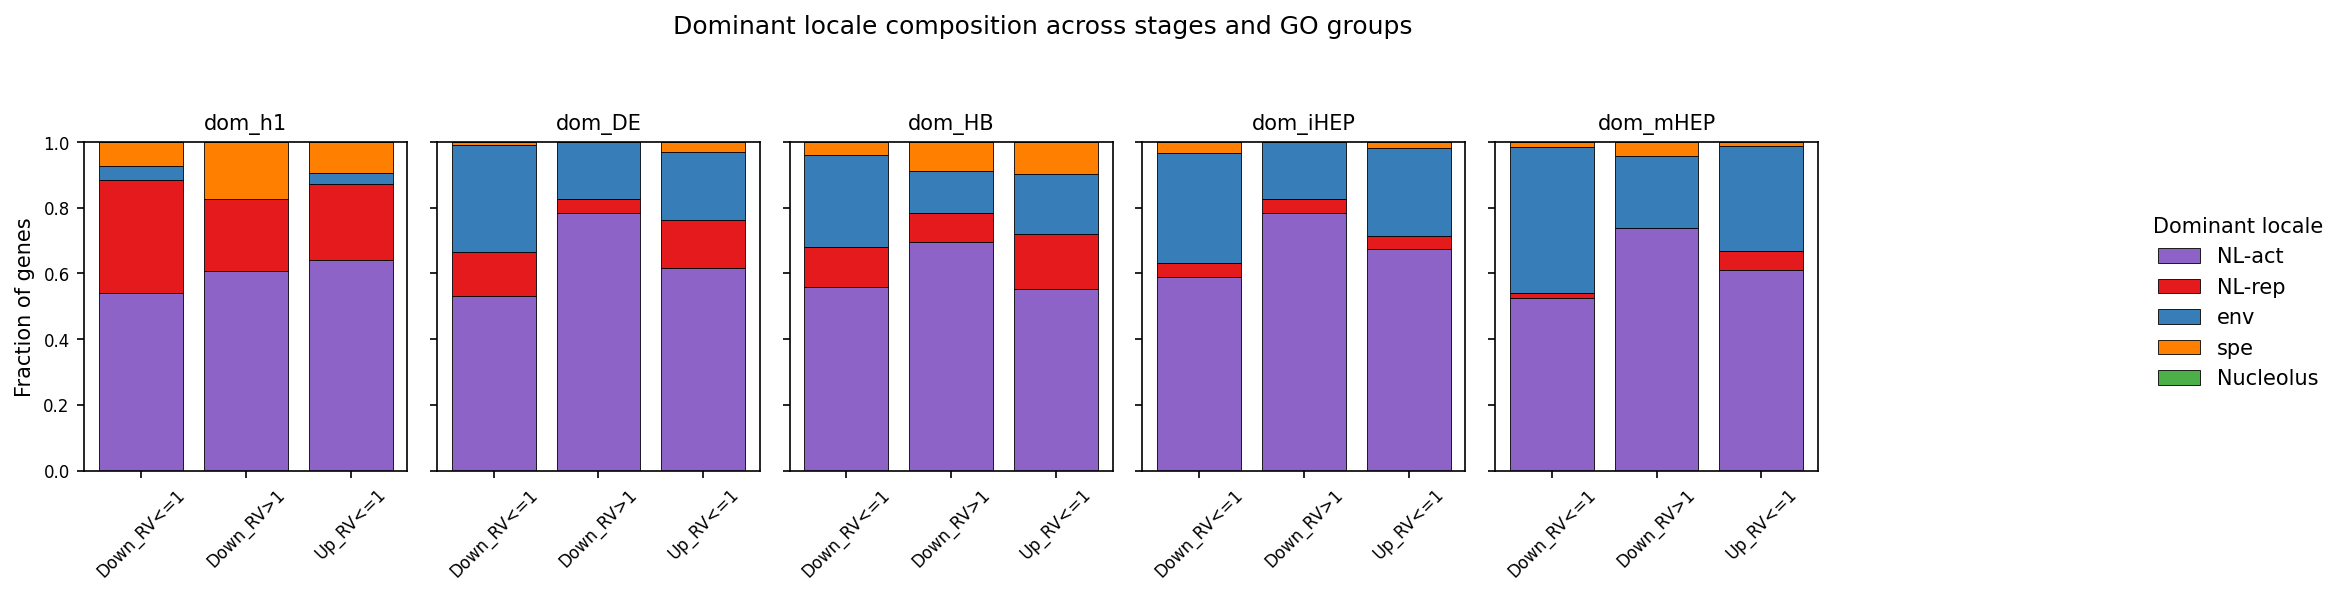

Saved figure to: /home/xiangru.huo-umw/scHiC/scripts/plot2/GO_group_dominant_locale_across_stages_stacked_bar.pdf


In [67]:
# ============================================================
# Stacked bar plot: dominant locale composition across stages

# ----------------------------
# Plot
# ----------------------------
fig, axes = plt.subplots(
    1,
    len(locale_cols),
    figsize=(14, 4),
    dpi=150,
    sharey=True
)

for ax, locale_col in zip(axes, locale_cols):

    plot_df = df.dropna(subset=["GO_group", locale_col]).copy()

    count_table = pd.crosstab(
        plot_df["GO_group"],
        plot_df[locale_col]
    ).reindex(index=go_order, columns=locale_order, fill_value=0)

    frac_table = count_table.div(count_table.sum(axis=1), axis=0).fillna(0)

    bottom = np.zeros(len(go_order))

    for locale in locale_order:
        values = frac_table[locale].values

        ax.bar(
            go_order,
            values,
            bottom=bottom,
            label=locale,
            color=locale_colors.get(locale, "gray"),
            edgecolor="black",
            linewidth=0.4
        )

        bottom += values

    ax.set_title(locale_col, fontsize=10)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)

axes[0].set_ylabel("Fraction of genes")

# one shared legend
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title="Dominant locale",
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
    frameon=False
)

fig.suptitle(
    "Dominant locale composition across stages and GO groups",
    fontsize=12
)

plt.tight_layout(rect=[0, 0, 0.88, 0.93])

save_fig_path = (
    "/home/xiangru.huo-umw/scHiC/scripts/plot2/"
    "GO_group_dominant_locale_across_stages_stacked_bar.pdf"
)

plt.savefig(save_fig_path, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {save_fig_path}")

In [ ]:
#check the locale change

In [11]:
locale_cols = ["dom_h1","dom_DE","dom_HB","dom_iHEP","dom_mHEP"]

sankey_df = (
    df[["gene","GO_group"] + locale_cols]
    .drop_duplicates("gene")
    .dropna(subset=locale_cols)
)

sankey_df

,gene,GO_group,dom_h1,dom_DE,dom_HB,dom_iHEP,dom_mHEP
0,ETV7,Up_RV<=1,spe,spe,spe,spe,spe
1,FYN,Up_RV<=1,NL-act,NL-act,env,env,env
2,WWTR1,Up_RV<=1,NL-rep,env,env,env,env
3,SERPINB1,Up_RV<=1,NL-act,NL-act,NL-act,NL-act,NL-act
4,TNC,Up_RV<=1,NL-rep,NL-rep,NL-act,NL-act,NL-act
...,...,...,...,...,...,...,...
312,RGS7BP,Down_RV<=1,NL-rep,env,env,env,env
313,MAPT,Down_RV<=1,spe,spe,spe,spe,NL-act
314,PCDH18,Down_RV<=1,env,env,env,env,env
315,IL1RAP,Down_RV<=1,NL-rep,NL-rep,NL-rep,env,env


In [18]:
transition_tables = []

for start, end in zip(locale_cols[:-1], locale_cols[1:]):

    tmp = (
        sankey_df
        .groupby(["GO_group", start, end])
        .size()
        .reset_index(name="value")
    )

    tmp["from_stage"] = start
    tmp["to_stage"] = end

    transition_tables.append(tmp)

transition_df = pd.concat(transition_tables, ignore_index=True)

transition_df.head()

,GO_group,dom_h1,dom_DE,value,from_stage,to_stage,dom_HB,dom_iHEP,dom_mHEP
0,Down_RV<=1,NL-act,NL-act,56,dom_h1,dom_DE,NaN,NaN,NaN
1,Down_RV<=1,NL-act,NL-rep,4,dom_h1,dom_DE,NaN,NaN,NaN
2,Down_RV<=1,NL-act,env,6,dom_h1,dom_DE,NaN,NaN,NaN
3,Down_RV<=1,NL-rep,NL-act,1,dom_h1,dom_DE,NaN,NaN,NaN
4,Down_RV<=1,NL-rep,NL-rep,11,dom_h1,dom_DE,NaN,NaN,NaN


In [22]:
import plotly.graph_objects as go

stages = ["H1", "DE", "HB", "iHEP", "mHEP"]
cols = ["dom_h1", "dom_DE", "dom_HB", "dom_iHEP", "dom_mHEP"]

go_order = ["Down_RV<=1", "Down_RV>1", "Up_RV<=1"]

for go_group in go_order:

    sub_df = sankey_df[sankey_df["GO_group"] == go_group].copy()

    # ----------------------------
    # Make nodes
    # ----------------------------
    nodes = []

    for stage, col in zip(stages, cols):
        for loc in sorted(sub_df[col].dropna().unique()):
            nodes.append(f"{stage}: {loc}")

    node_dict = {n: i for i, n in enumerate(nodes)}

    # ----------------------------
    # Build links
    # ----------------------------
    source = []
    target = []
    value = []

    for stage1, col1, stage2, col2 in zip(
        stages[:-1],
        cols[:-1],
        stages[1:],
        cols[1:]
    ):

        tmp = (
            sub_df
            .groupby([col1, col2])
            .size()
            .reset_index(name="count")
        )

        for _, r in tmp.iterrows():

            source.append(node_dict[f"{stage1}: {r[col1]}"])
            target.append(node_dict[f"{stage2}: {r[col2]}"])
            value.append(r["count"])

    # ----------------------------
    # Plot
    # ----------------------------
    fig = go.Figure(go.Sankey(
        node=dict(
            pad=18,
            thickness=20,
            label=nodes
        ),
        link=dict(
            source=source,
            target=target,
            value=value
        )
    ))

    fig.update_layout(
        title=f"Dominant locale transitions: {go_group}",
        width=700,
        height=500,
        font_size=12
    )

    fig.show()
    
# save
    safe_name = (go_group.replace("<=", "le").replace(">", "gt").replace("/", "_"))

    fig.write_image(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/{safe_name}_dominant_locale_sankey.pdf",width=1200,height=600,scale=2)

# Housekeeping 

In [35]:
#load housekeeping gene dataset from PMID: 32663312
file = "/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/HK_genes_Table1.xlsx"

# Read all sheets
hk_sheets = pd.read_excel(file, sheet_name=None)

# Convert each sheet to a gene set
hk_gene_sets = {}

for sheet_name, df in hk_sheets.items():
    # Replace "Gene" with your actual gene column name
    genes = (
        df["Gene"]
        .dropna()
        .astype(str)
        .str.strip()
        .str.upper()
    )

    hk_gene_sets[sheet_name] = set(genes)

# Check sizes
for name, genes in hk_gene_sets.items():
    print(name, len(genes))

Common gene 802
Gene Model 1003


In [36]:
#get common HK genes list
common_genes = hk_gene_sets[list(hk_gene_sets.keys())[0]] & hk_gene_sets[list(hk_gene_sets.keys())[1]]

print(f"Common genes: {len(common_genes)}")

Common genes: 802


In [55]:
#load gene locale information
file = "/home/xiangru.huo-umw/scHiC/scripts/scRNA_matrix/dominant_locale_per_gene_5stages_inclSpeckleNucleoli.csv"

gene_locale = pd.read_csv(file)

In [61]:
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

# ============================================================
# Load / merge ES gene data with dominant locale
# ============================================================

df = gene_bin_subcompartments["ES"].copy()

# merge gene locale info by gene
df = df.merge(
    gene_locale,
    on="gene",
    how="left"
)

keep_cols = [
    "gene",
    "stage_x",
    "residual_variance",
    "bulk_tpm",
    "entropy",
    "dom_h1",
    "dom_DE",
    "dom_HB",
    "dom_iHEP",
    "dom_mHEP",
    "norm_rad"
]

df = df[keep_cols].copy()

# filter TPM > 1
df = df[df["bulk_tpm"] > 1]

# clean
df = df.dropna(subset=[
    "gene",
    "residual_variance",
    "bulk_tpm",
    "norm_rad",
    "dom_h1"
])

df["gene_norm"] = (
    df["gene"]
    .astype(str)
    .str.strip()
    .str.upper()
)

df["RV_cateloge"] = np.where(
    df["residual_variance"] > 1,
    "high_variance",
    "less_variance"
)

# locale order
locale_order = ["env", "spe", "nuc", "NL-act", "NL-rep"]

# keep only locales present
locale_order = [x for x in locale_order if x in df["dom_h1"].unique()]

Skip nuc | less_variance: n_hits=0, n_miss=2
Skip nuc | high_variance: n_hits=0, n_miss=1
Running ES y-limit: (-0.39215686274509787, 0.8235294117647055)
logTPM y-limit: (0, 9.809283604745557)
Saved GSEA curve dataframe to: /home/xiangru.huo-umw/scHiC/scripts/plot2/ES_HK_GSEA_less_vs_high_variance_dom_h1_running_curves.tsv


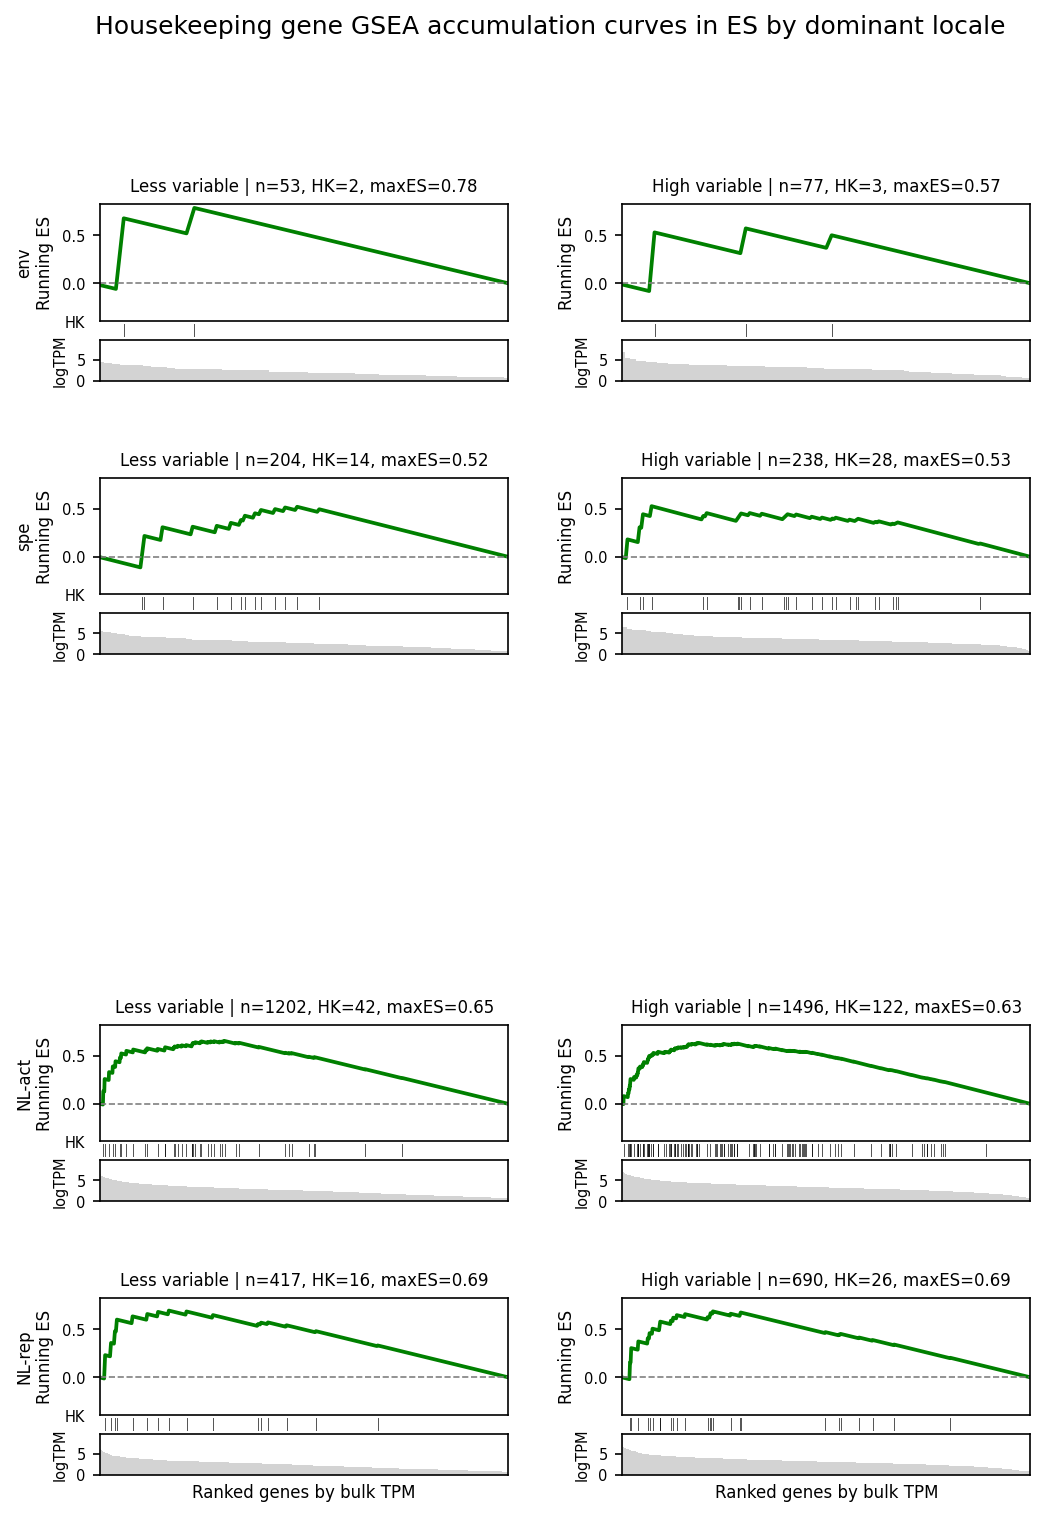

Saved figure to: /home/xiangru.huo-umw/scHiC/scripts/plot2/ES_HK_GSEA_less_vs_high_variance_dom_h1_with_logTPM_sameY.pdf


In [62]:
# ============================================================
# Housekeeping GSEA accumulation curves
# grouped by dom_h1 instead of subcompartment
# 5 x 2 layout: less_variance vs high_variance
# same y-axis range across all panels
# ============================================================

# ----------------------------
# Settings
# ----------------------------
hk_common = {str(g).strip().upper() for g in common_genes}

rv_order = ["less_variance", "high_variance"]
rv_titles = {
    "less_variance": "Less variable",
    "high_variance": "High variable"
}

rank_col = "bulk_tpm"

df_gsea = df.copy()
df_gsea = df_gsea.dropna(subset=[
    "gene_norm",
    "bulk_tpm",
    "dom_h1",
    "RV_cateloge"
])

# ----------------------------
# Build GSEA curve dataframe
# ----------------------------
gsea_curve_dfs = []

for locale in locale_order:
    for rv_cat in rv_order:

        sub = df_gsea[
            (df_gsea["dom_h1"] == locale) &
            (df_gsea["RV_cateloge"] == rv_cat)
        ].copy()

        sub = (
            sub.sort_values(rank_col, ascending=False)
               .drop_duplicates("gene_norm")
               .reset_index(drop=True)
        )

        if len(sub) == 0:
            print(f"Skip {locale} | {rv_cat}: no genes")
            continue

        genes_ranked = sub["gene_norm"].tolist()
        scores = sub[rank_col].values

        hits = np.array([g in hk_common for g in genes_ranked])

        n_hits = hits.sum()
        n_miss = len(hits) - n_hits

        if n_hits == 0 or n_miss == 0:
            print(f"Skip {locale} | {rv_cat}: n_hits={n_hits}, n_miss={n_miss}")
            continue

        hit_weights = np.abs(scores) * hits
        hit_weights = hit_weights / hit_weights.sum()

        miss_weights = (~hits) / n_miss

        running_es = np.cumsum(hit_weights - miss_weights)

        curve_df = pd.DataFrame({
            "rank": np.arange(1, len(sub) + 1),
            "gene": genes_ranked,
            "bulk_tpm": scores,
            "logTPM": np.log1p(scores),
            "is_HK_common": hits,
            "running_ES": running_es,
            "dom_h1": locale,
            "RV_cateloge": rv_cat,
            "n_genes": len(sub),
            "n_HK": n_hits,
            "max_ES": running_es.max(),
            "min_ES": running_es.min()
        })

        gsea_curve_dfs.append(curve_df)

gsea_curve_df = pd.concat(gsea_curve_dfs, ignore_index=True)

# ----------------------------
# Same y-axis ranges
# ----------------------------
max_abs_es = np.nanmax(np.abs(gsea_curve_df["running_ES"]))
es_ylim = (-0.5 * max_abs_es, 1.05 * max_abs_es)

logtpm_ylim = (0, 1.05 * np.nanmax(gsea_curve_df["logTPM"]))

print("Running ES y-limit:", es_ylim)
print("logTPM y-limit:", logtpm_ylim)

# Save table
save_curve_path = (
    "/home/xiangru.huo-umw/scHiC/scripts/plot2/"
    "ES_HK_GSEA_less_vs_high_variance_dom_h1_running_curves.tsv"
)

gsea_curve_df.to_csv(save_curve_path, sep="\t", index=False)
print(f"Saved GSEA curve dataframe to: {save_curve_path}")


# ============================================================
# Plot combined figure
# ============================================================

n_rows = len(locale_order)
n_cols = len(rv_order)

fig = plt.figure(figsize=(8, 2.2 * n_rows), dpi=150)

outer_gs = GridSpec(
    n_rows,
    n_cols,
    figure=fig,
    wspace=0.28,
    hspace=0.55
)

for i, locale in enumerate(locale_order):
    for j, rv_cat in enumerate(rv_order):

        plot_df = gsea_curve_df[
            (gsea_curve_df["dom_h1"] == locale) &
            (gsea_curve_df["RV_cateloge"] == rv_cat)
        ].copy()

        if plot_df.empty:
            continue

        n_genes = plot_df["n_genes"].iloc[0]
        n_HK = plot_df["n_HK"].iloc[0]
        max_es = plot_df["running_ES"].max()

        inner_gs = GridSpecFromSubplotSpec(
            3,
            1,
            subplot_spec=outer_gs[i, j],
            height_ratios=[4.0, 0.45, 1.4],
            hspace=0.05
        )

        # Top: running ES curve
        ax_es = fig.add_subplot(inner_gs[0])

        ax_es.plot(
            plot_df["rank"],
            plot_df["running_ES"],
            color="green",
            lw=1.8
        )

        ax_es.axhline(0, color="gray", lw=0.8, ls="--")
        ax_es.set_ylim(*es_ylim)
        ax_es.set_xticks([])

        if j == 0:
            ax_es.set_ylabel(f"{locale}\nRunning ES", fontsize=8)
        else:
            ax_es.set_ylabel("Running ES", fontsize=8)

        ax_es.set_title(
            f"{rv_titles[rv_cat]} | n={n_genes}, HK={n_HK}, maxES={max_es:.2f}",
            fontsize=8
        )

        ax_es.tick_params(axis="both", labelsize=7)

        # Middle: HK hit ticks
        ax_hit = fig.add_subplot(inner_gs[1], sharex=ax_es)

        hk_pos = plot_df.loc[plot_df["is_HK_common"], "rank"]

        for x in hk_pos:
            ax_hit.axvline(
                x,
                ymin=0,
                ymax=1,
                color="black",
                lw=0.45,
                alpha=0.7
            )

        ax_hit.set_yticks([])
        ax_hit.set_xticks([])

        if j == 0:
            ax_hit.set_ylabel("HK", rotation=0, labelpad=12, fontsize=7)

        for spine in ax_hit.spines.values():
            spine.set_visible(False)

        # Bottom: log(TPM+1) bars
        ax_tpm = fig.add_subplot(inner_gs[2], sharex=ax_es)

        ax_tpm.bar(
            plot_df["rank"],
            plot_df["logTPM"],
            width=1.0,
            color="lightgray",
            edgecolor="none"
        )

        ax_tpm.set_ylim(*logtpm_ylim)
        ax_tpm.set_ylabel("logTPM", fontsize=7)

        if i == n_rows - 1:
            ax_tpm.set_xlabel("Ranked genes by bulk TPM", fontsize=8)
        else:
            ax_tpm.set_xlabel("")

        ax_tpm.tick_params(axis="both", labelsize=7)

        ax_tpm.set_xlim(
            plot_df["rank"].min(),
            plot_df["rank"].max()
        )

fig.suptitle(
    "Housekeeping gene GSEA accumulation curves in ES by dominant locale",
    fontsize=12,
    y=0.995
)

save_fig_path = (
    "/home/xiangru.huo-umw/scHiC/scripts/plot2/"
    "ES_HK_GSEA_less_vs_high_variance_dom_h1_with_logTPM_sameY.pdf"
)

plt.savefig(save_fig_path, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {save_fig_path}")

In [ ]:
# ============================================================
# Load / merge ES gene data with dominant locale
# ============================================================

df = gene_bin_subcompartments["ES"].copy()

# merge gene locale info by gene
df = df.merge(
    gene_locale,
    on="gene",
    how="left"
)

keep_cols = [
    "gene",
    "stage_x",
    "residual_variance",
    "bulk_tpm",
    "entropy",
    "subcompartment"
]

df = df[keep_cols].copy()

# filter TPM > 1
df = df[df["bulk_tpm"] > 1]

# clean
df = df.dropna(subset=[
    "gene",
    "residual_variance",
    "bulk_tpm",
    "norm_rad",
    "subcompartment"
])

df["gene_norm"] = (
    df["gene"]
    .astype(str)
    .str.strip()
    .str.upper()
)

df["RV_cateloge"] = np.where(
    df["residual_variance"] > 1,
    "high_variance",
    "less_variance"
)

# locale order
locale_order = ["A1", "A2", "B1", "Quies", "Inactive"]

# keep only locales present
locale_order = [x for x in locale_order if x in df["subcompartment"].unique()]

Running ES y-limit: (-0.5, 1.05)
logTPM y-limit: (0, 9.023684420257142)
Saved GSEA curve dataframe to: /home/xiangru.huo-umw/scHiC/scripts/plot2/ES_HK_GSEA_less_vs_high_variance_running_curves.tsv


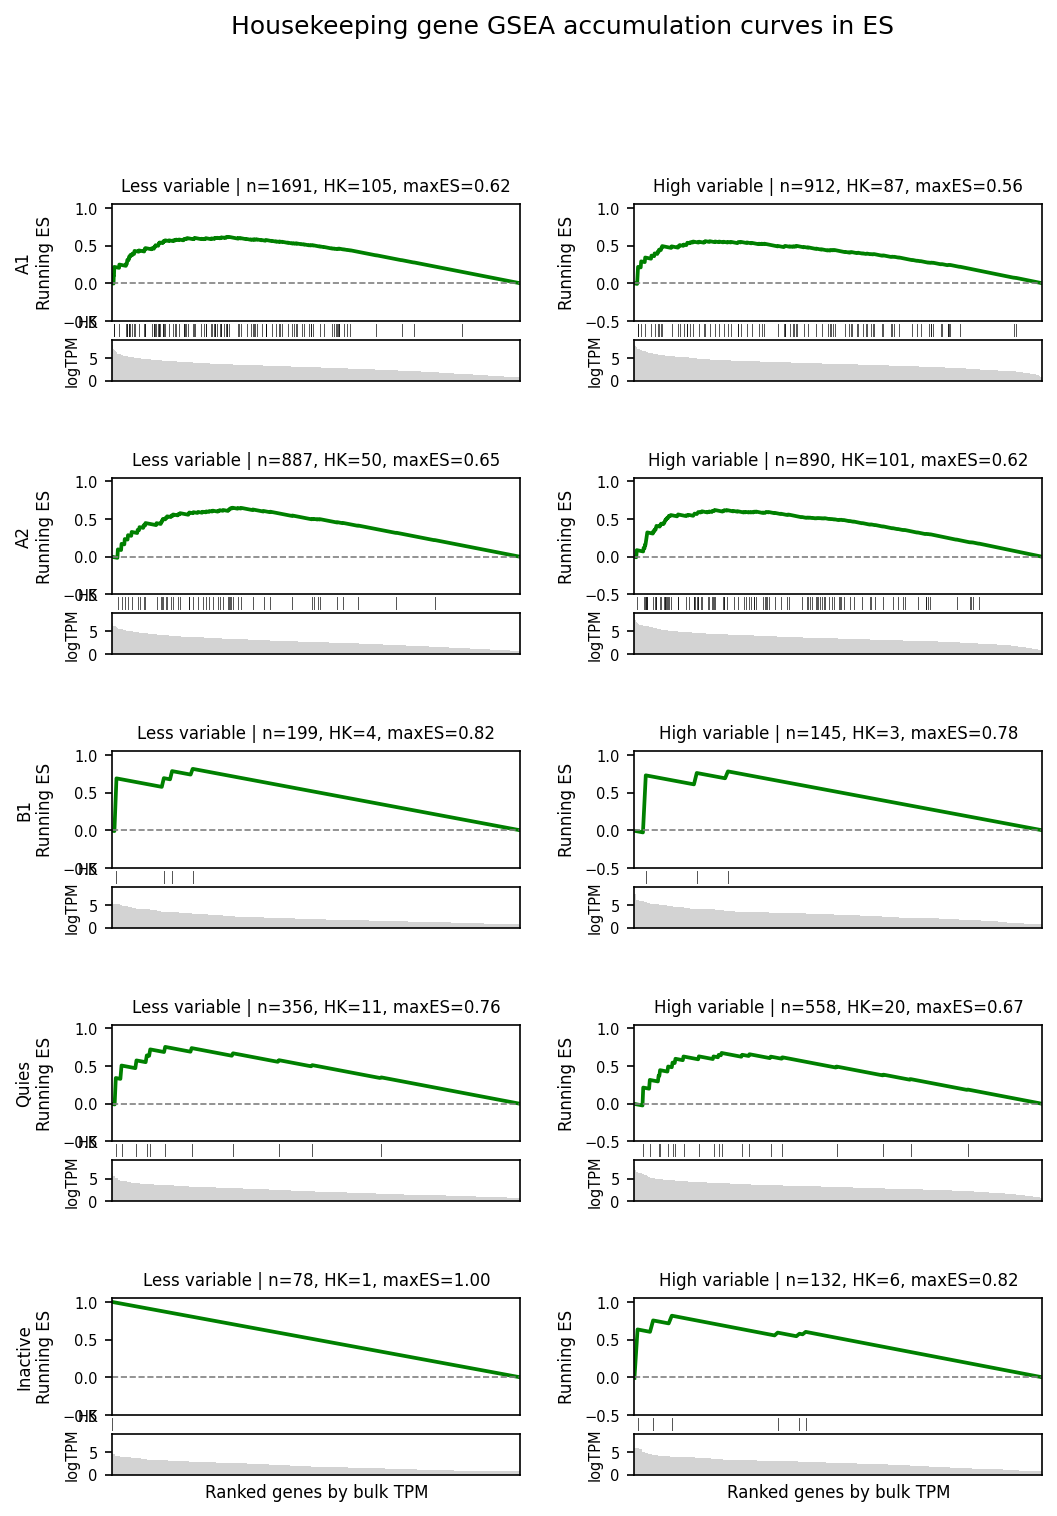

Saved figure to: /home/xiangru.huo-umw/scHiC/scripts/plot2/ES_HK_GSEA_less_vs_high_variance_5x2_with_logTPM_sameY.pdf


In [49]:
# ============================================================
# Housekeeping GSEA accumulation curves
# 5 x 2 layout: less_variance vs high_variance
# same y-axis range across all panels
# ============================================================
# ----------------------------
# Settings
# ----------------------------
hk_common = {str(g).strip().upper() for g in common_genes}

rv_order = ["less_variance", "high_variance"]
rv_titles = {
    "less_variance": "Less variable",
    "high_variance": "High variable"
}

rank_col = "bulk_tpm"

df_gsea = df.copy()
df_gsea = df_gsea.dropna(subset=[
    "gene_norm",
    "bulk_tpm",
    "subcompartment",
    "RV_cateloge"
])

# ----------------------------
# Build GSEA curve dataframe
# ----------------------------
gsea_curve_dfs = []

for subcomp in subcomp_order:
    for rv_cat in rv_order:

        sub = df_gsea[
            (df_gsea["subcompartment"] == subcomp) &
            (df_gsea["RV_cateloge"] == rv_cat)
        ].copy()

        sub = (
            sub.sort_values(rank_col, ascending=False)
               .drop_duplicates("gene_norm")
               .reset_index(drop=True)
        )

        if len(sub) == 0:
            print(f"Skip {subcomp} | {rv_cat}: no genes")
            continue

        genes_ranked = sub["gene_norm"].tolist()
        scores = sub[rank_col].values

        hits = np.array([g in hk_common for g in genes_ranked])

        n_hits = hits.sum()
        n_miss = len(hits) - n_hits

        if n_hits == 0 or n_miss == 0:
            print(f"Skip {subcomp} | {rv_cat}: n_hits={n_hits}, n_miss={n_miss}")
            continue

        hit_weights = np.abs(scores) * hits
        hit_weights = hit_weights / hit_weights.sum()

        miss_weights = (~hits) / n_miss

        running_es = np.cumsum(hit_weights - miss_weights)

        curve_df = pd.DataFrame({
            "rank": np.arange(1, len(sub) + 1),
            "gene": genes_ranked,
            "bulk_tpm": scores,
            "logTPM": np.log1p(scores),
            "is_HK_common": hits,
            "running_ES": running_es,
            "subcompartment": subcomp,
            "RV_cateloge": rv_cat,
            "n_genes": len(sub),
            "n_HK": n_hits,
            "max_ES": running_es.max(),
            "min_ES": running_es.min()
        })

        gsea_curve_dfs.append(curve_df)

gsea_curve_df = pd.concat(gsea_curve_dfs, ignore_index=True)

# ----------------------------
# Same y-axis ranges
# ----------------------------
max_abs_es = np.nanmax(np.abs(gsea_curve_df["running_ES"]))
es_ylim = (-0.5 * max_abs_es, 1.05 * max_abs_es)

logtpm_ylim = (0, 1.05 * np.nanmax(gsea_curve_df["logTPM"]))

print("Running ES y-limit:", es_ylim)
print("logTPM y-limit:", logtpm_ylim)

# Save table
save_curve_path = (
    "/home/xiangru.huo-umw/scHiC/scripts/plot2/"
    "ES_HK_GSEA_less_vs_high_variance_running_curves.tsv"
)

gsea_curve_df.to_csv(save_curve_path, sep="\t", index=False)
print(f"Saved GSEA curve dataframe to: {save_curve_path}")


# ============================================================
# Plot 5 x 2 combined figure
# ============================================================

n_rows = len(subcomp_order)
n_cols = len(rv_order)

fig = plt.figure(figsize=(8, 2.2 * n_rows), dpi=150)

outer_gs = GridSpec(
    n_rows,
    n_cols,
    figure=fig,
    wspace=0.28,
    hspace=0.55
)

for i, subcomp in enumerate(subcomp_order):
    for j, rv_cat in enumerate(rv_order):

        plot_df = gsea_curve_df[
            (gsea_curve_df["subcompartment"] == subcomp) &
            (gsea_curve_df["RV_cateloge"] == rv_cat)
        ].copy()

        if plot_df.empty:
            continue

        n_genes = plot_df["n_genes"].iloc[0]
        n_HK = plot_df["n_HK"].iloc[0]
        max_es = plot_df["running_ES"].max()

        inner_gs = GridSpecFromSubplotSpec(
            3,
            1,
            subplot_spec=outer_gs[i, j],
            height_ratios=[4.0, 0.45, 1.4],
            hspace=0.05
        )

        # ------------------------
        # Top: running ES curve
        # ------------------------
        ax_es = fig.add_subplot(inner_gs[0])

        ax_es.plot(
            plot_df["rank"],
            plot_df["running_ES"],
            color="green",
            lw=1.8
        )

        ax_es.axhline(0, color="gray", lw=0.8, ls="--")
        ax_es.set_ylim(*es_ylim)
        ax_es.set_xticks([])

        if j == 0:
            ax_es.set_ylabel(f"{subcomp}\nRunning ES", fontsize=8)
        else:
            ax_es.set_ylabel("Running ES", fontsize=8)

        ax_es.set_title(
            f"{rv_titles[rv_cat]} | n={n_genes}, HK={n_HK}, maxES={max_es:.2f}",
            fontsize=8
        )

        ax_es.tick_params(axis="both", labelsize=7)

        # ------------------------
        # Middle: HK hit ticks
        # ------------------------
        ax_hit = fig.add_subplot(inner_gs[1], sharex=ax_es)

        hk_pos = plot_df.loc[plot_df["is_HK_common"], "rank"]

        for x in hk_pos:
            ax_hit.axvline(
                x,
                ymin=0,
                ymax=1,
                color="black",
                lw=0.45,
                alpha=0.7
            )

        ax_hit.set_yticks([])
        ax_hit.set_xticks([])

        if j == 0:
            ax_hit.set_ylabel("HK", rotation=0, labelpad=12, fontsize=7)

        for spine in ax_hit.spines.values():
            spine.set_visible(False)

        # ------------------------
        # Bottom: log(TPM+1) bars
        # ------------------------
        ax_tpm = fig.add_subplot(inner_gs[2], sharex=ax_es)

        ax_tpm.bar(
            plot_df["rank"],
            plot_df["logTPM"],
            width=1.0,
            color="lightgray",
            edgecolor="none"
        )

        ax_tpm.set_ylim(*logtpm_ylim)
        ax_tpm.set_ylabel("logTPM", fontsize=7)

        if i == n_rows - 1:
            ax_tpm.set_xlabel("Ranked genes by bulk TPM", fontsize=8)
        else:
            ax_tpm.set_xlabel("")

        ax_tpm.tick_params(axis="both", labelsize=7)

        ax_tpm.set_xlim(
            plot_df["rank"].min(),
            plot_df["rank"].max()
        )

fig.suptitle(
    "Housekeeping gene GSEA accumulation curves in ES",
    fontsize=12,
    y=0.995
)

save_fig_path = (
    "/home/xiangru.huo-umw/scHiC/scripts/plot2/"
    "ES_HK_GSEA_less_vs_high_variance_5x2_with_logTPM_sameY.pdf"
)

plt.savefig(save_fig_path, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {save_fig_path}")

# Developmental GO term

In [ ]:
#GO analysis
from gprofiler import GProfiler

# --- Config ---
output_dir = "/home/xiangru.huo-umw/scHiC/scripts/inter_file/"
os.makedirs(output_dir, exist_ok=True)

# --- DEG cutoff ---
log2fc_threshold = np.log2(1.1)  # 10% FC
pval_threshold = 0.05

# --- Assign DEG labels ---
merged['DEG_relaxed'] = 'n.s.'
merged.loc[(merged['log2FC_bulk_tpm'] > log2fc_threshold) & (merged['pval'] < pval_threshold), 'DEG_relaxed'] = 'up'
merged.loc[(merged['log2FC_bulk_tpm'] < -log2fc_threshold) & (merged['pval'] < pval_threshold), 'DEG_relaxed'] = 'down'

# --- Define categories ---
ordered_categories = [
    'SigUp_RV<=1', 'SigUp_RV>1',
    'NonSigUp_RV<=1', 'NonSigUp_RV>1',
    'SigDown_RV<=1', 'SigDown_RV>1',
    'NonSigDown_RV<=1', 'NonSigDown_RV>1'
]


# --- Extract gene lists ---
gene_lists = {
    category: merged[merged['category'] == category]['gene'].dropna().unique().tolist()
    for category in ordered_categories
}

# --- Define background ---
background_genes = merged['gene'].dropna().unique().tolist()

# --- Run gProfiler ---
gp = GProfiler(return_dataframe=True)
all_results = []

for category, genes in gene_lists.items():
    if len(genes) >= 5:
        res = gp.profile(
            organism='hsapiens',
            query=genes,
            sources=['GO:BP'],
            background=background_genes,
            no_evidences=False   # <<< This includes 'intersections' with gene lists
        )
        res['category'] = category
        all_results.append(res)
    else:
        print(f"⚠️ Skipping {category} (only {len(genes)} genes)")

# --- Combine results ---
combined = pd.concat(all_results, ignore_index=True)
combined['-log10(padj)'] = -np.log10(combined['p_value'])
combined = combined[combined['term_size'] <= 1000]  # Optional: filter very broad terms

# --- Get top 15 terms per group ---
top_combined = (
    combined.sort_values(['category', 'p_value'])
    .groupby('category')
    .head(15)
)

# --- Save results (including intersections) ---
top_combined.to_csv(
    os.path.join(output_dir, "top15_terms_per_category.tsv"),
    sep='\t', index=False,
    columns=['category', 'name', 'term_size', 'intersection_size', 'p_value', '-log10(padj)', 'intersections']
)

combined.to_csv(
    os.path.join(output_dir, "full_GO_enrichment_results.tsv"),
    sep='\t', index=False,
    columns=['category', 'name', 'term_size', 'intersection_size', 'p_value', '-log10(padj)', 'intersections']
)

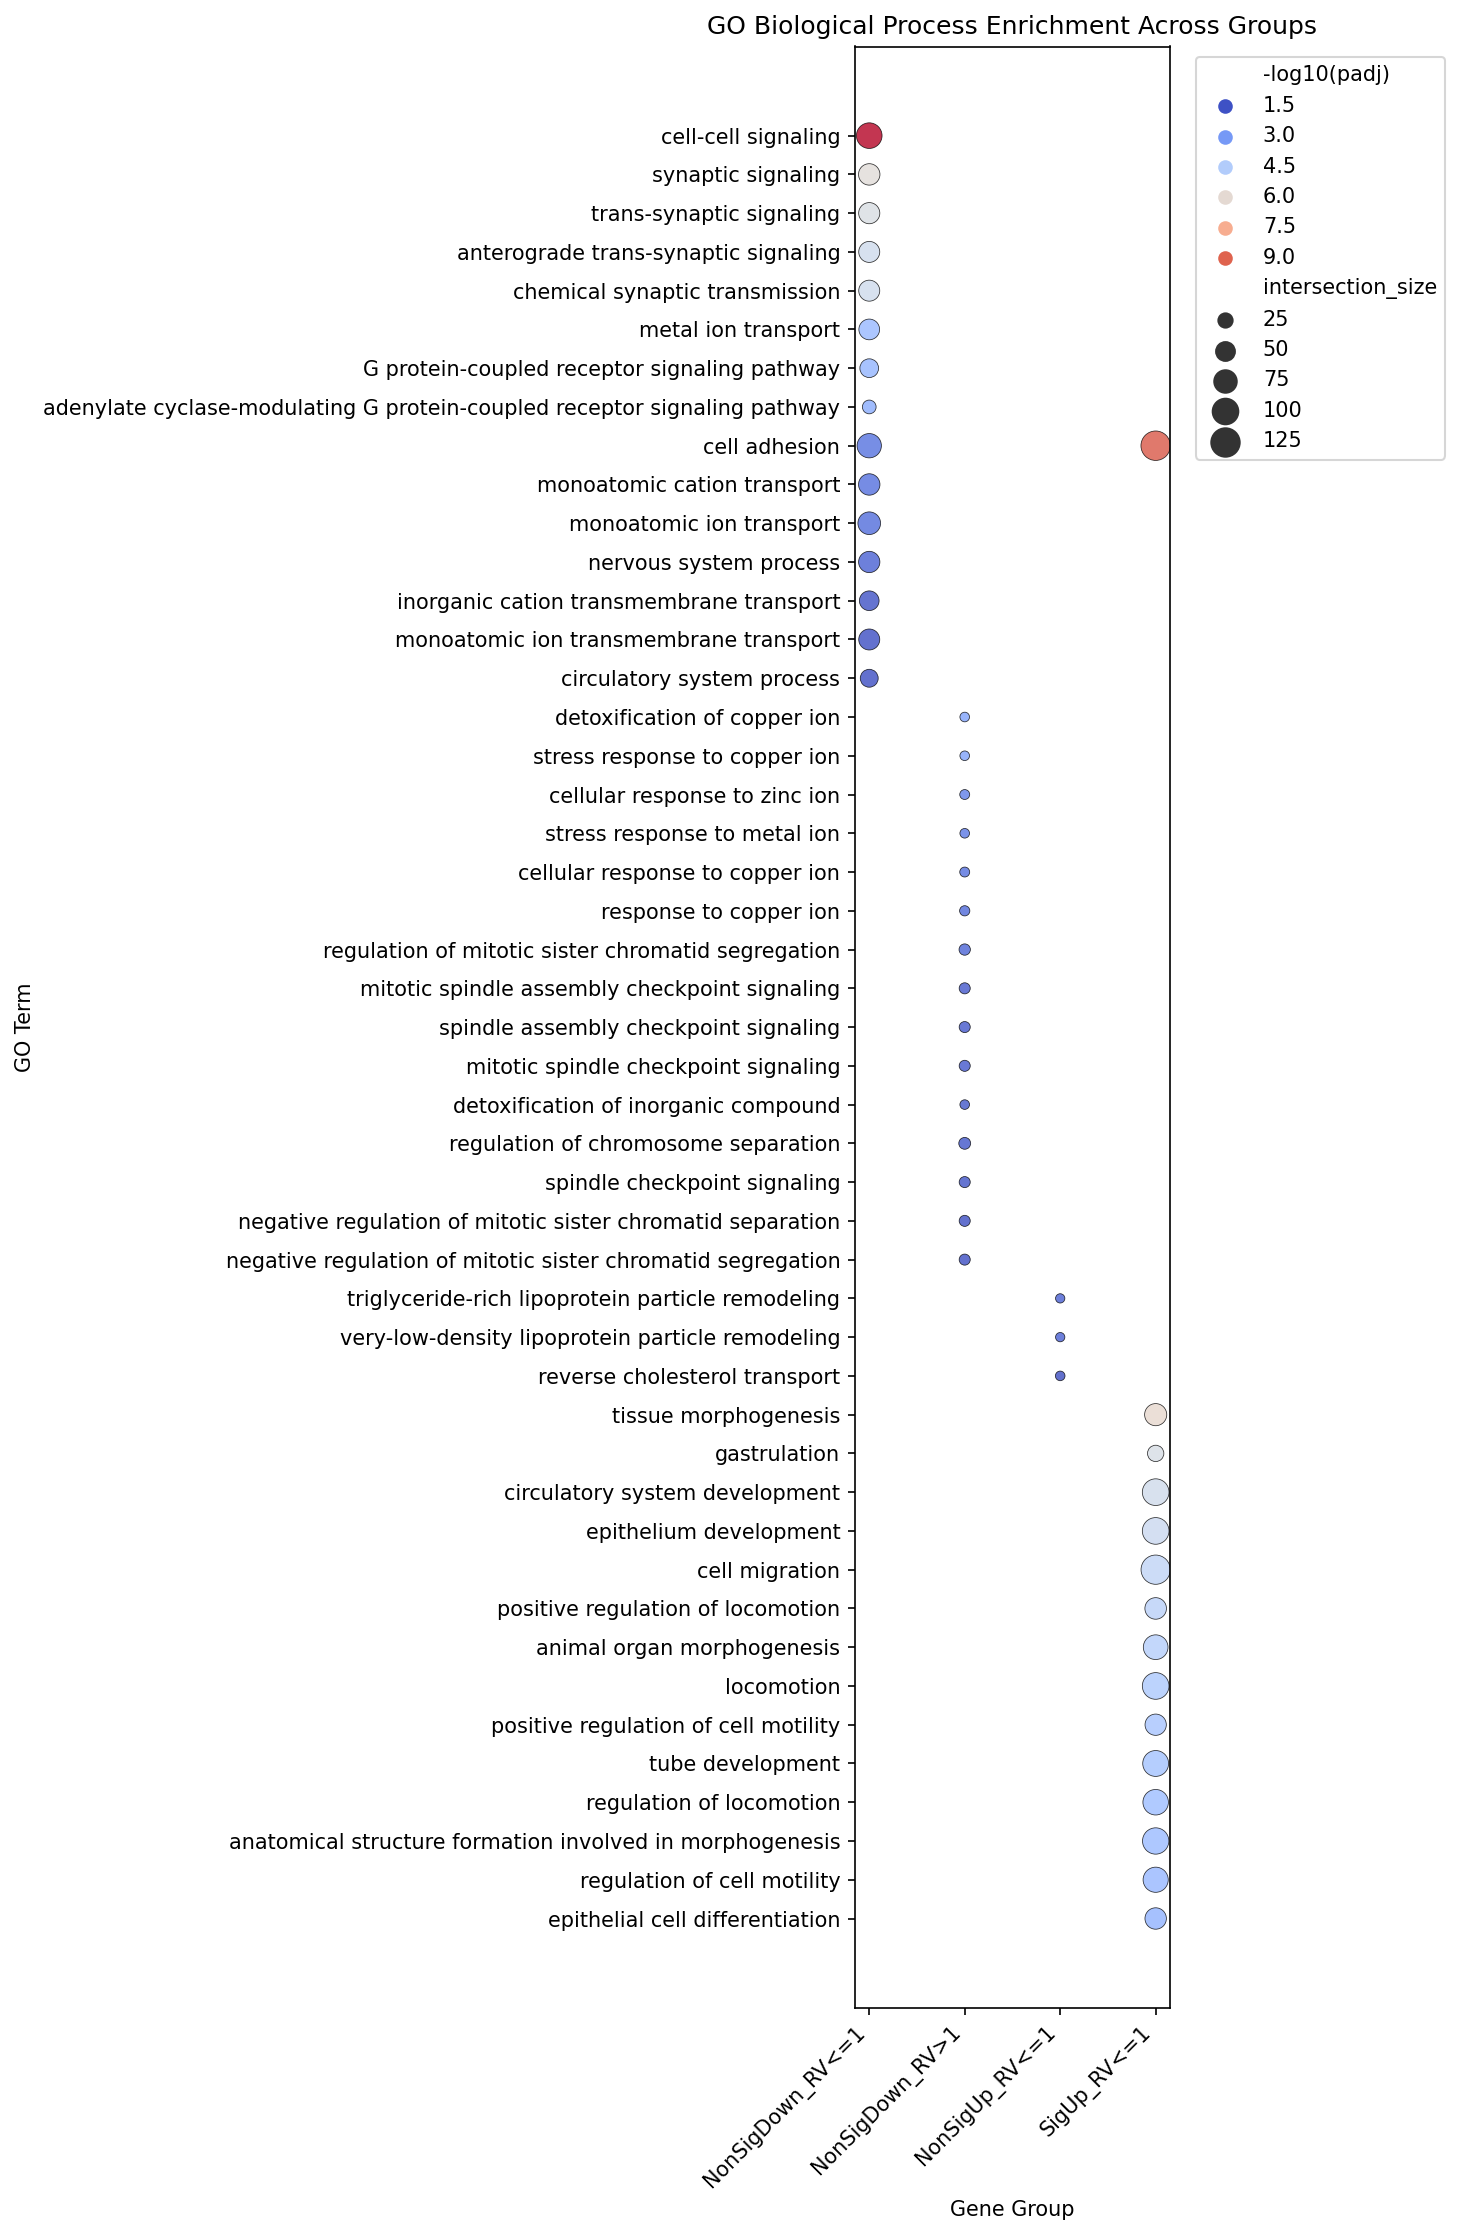

In [62]:
# Plot bubble chart
plt.figure(figsize=(8, 15), dpi=150)
sns.scatterplot(
    data=top_combined,
    x='category',
    y='name',
    size='intersection_size',
    hue='-log10(padj)',
    palette='coolwarm',
    sizes=(20, 200),
    edgecolor='black',
    alpha=0.8,
    legend='brief'
)
plt.title("GO Biological Process Enrichment Across Groups")
plt.xticks(rotation=45, ha='right')
plt.ylabel("GO Term")
plt.xlabel("Gene Group")
plt.tight_layout()
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/GO_analysis_betweenRV<1and>1.pdf", format='pdf')
plt.show()

In [39]:
#combined sig and non-sign
from gprofiler import GProfiler

# --- Config ---
output_dir = "/home/xiangru.huo-umw/scHiC/scripts/inter_file/"
os.makedirs(output_dir, exist_ok=True)

# --- Create 4 groups based on fold change and residual variance ---
merged['group4'] = 'Other'

merged.loc[(merged['log2FC_bulk_tpm'] > 1) & (merged[f'residual_variance_{stage1}'] > 1), 'group4'] = 'Up_RV>1'
merged.loc[(merged['log2FC_bulk_tpm'] > 1) & (merged[f'residual_variance_{stage1}'] <= 1), 'group4'] = 'Up_RV<=1'
merged.loc[(merged['log2FC_bulk_tpm'] < -1) & (merged[f'residual_variance_{stage1}'] > 1), 'group4'] = 'Down_RV>1'
merged.loc[(merged['log2FC_bulk_tpm'] < -1) & (merged[f'residual_variance_{stage1}'] <= 1), 'group4'] = 'Down_RV<=1'

ordered_groups = ['Up_RV>1', 'Up_RV<=1', 'Down_RV>1', 'Down_RV<=1']

# --- Save gene lists and run gProfiler ---
background_genes = merged['gene'].dropna().unique().tolist()

gp = GProfiler(return_dataframe=True)
all_results = []
gene_counts = {}

for group in ordered_groups:
    genes = merged[merged['group4'] == group]['gene'].dropna().unique().tolist()
    gene_counts[group] = len(genes)

    # Save gene list
    with open(os.path.join(output_dir, f"{group}_genes.txt"), 'w') as f:
        for g in genes:
            f.write(f"{g}\n")

    # Run GO enrichment
    if len(genes) >= 5:
        res = gp.profile(
            organism='hsapiens',
            query=genes,
            sources=['GO:BP'],
            background=background_genes,
            no_evidences=False
        )
        res['Group'] = group
        all_results.append(res)
    else:
        print(f"⚠️ Skipping {group} (only {len(genes)} genes)")

# --- Save gene counts ---
gene_count_df = pd.DataFrame.from_dict(gene_counts, orient='index', columns=['gene_count'])
gene_count_df.to_csv(os.path.join(output_dir, "gene_counts_per_group.tsv"), sep='\t')

# --- Combine GO results ---
combined = pd.concat(all_results, ignore_index=True)
combined['-log10(padj)'] = -np.log10(combined['p_value'])
combined = combined[combined['term_size'] <= 1000]

top_combined = (
    combined.sort_values(['Group', 'p_value'])
    .groupby('Group')
    .head(15)
)

# --- Save results ---
top_combined.to_csv(
    os.path.join(output_dir, "top15_GO_terms_4groups.tsv"),
    sep='\t', index=False,
    columns=['Group', 'name', 'term_size', 'intersection_size', 'p_value', '-log10(padj)', 'intersections']
)

combined.to_csv(
    os.path.join(output_dir, "full_GO_results_4groups.tsv"),
    sep='\t', index=False,
    columns=['Group', 'name', 'term_size', 'intersection_size', 'p_value', '-log10(padj)', 'intersections']
)

INFO:fontTools.subset:maxp pruned
INFO:fontTools.subset:cmap pruned
INFO:fontTools.subset:kern dropped
INFO:fontTools.subset:post pruned
INFO:fontTools.subset:FFTM dropped
INFO:fontTools.subset:GPOS pruned
INFO:fontTools.subset:GSUB pruned
INFO:fontTools.subset:name pruned
INFO:fontTools.subset:glyf pruned
INFO:fontTools.subset:Added gid0 to subset
INFO:fontTools.subset:Added first four glyphs to subset
INFO:fontTools.subset:Closing glyph list over 'GSUB': 58 glyphs before
INFO:fontTools.subset:Glyph names: ['.notdef', '.null', 'B', 'D', 'E', 'G', 'L', 'O', 'P', 'R', 'T', 'U', 'V', 'a', 'b', 'c', 'd', 'e', 'eight', 'equal', 'f', 'five', 'four', 'g', 'greater', 'h', 'hyphen', 'i', 'j', 'k', 'l', 'less', 'm', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'period', 'plus', 'r', 's', 'seven', 'six', 'slash', 'space', 't', 'two', 'u', 'underscore', 'v', 'w', 'x', 'y', 'z', 'zero']
INFO:fontTools.subset:Glyph IDs:   [0, 1, 2, 3, 11, 12, 14, 16, 17, 18, 19, 20, 21, 23, 

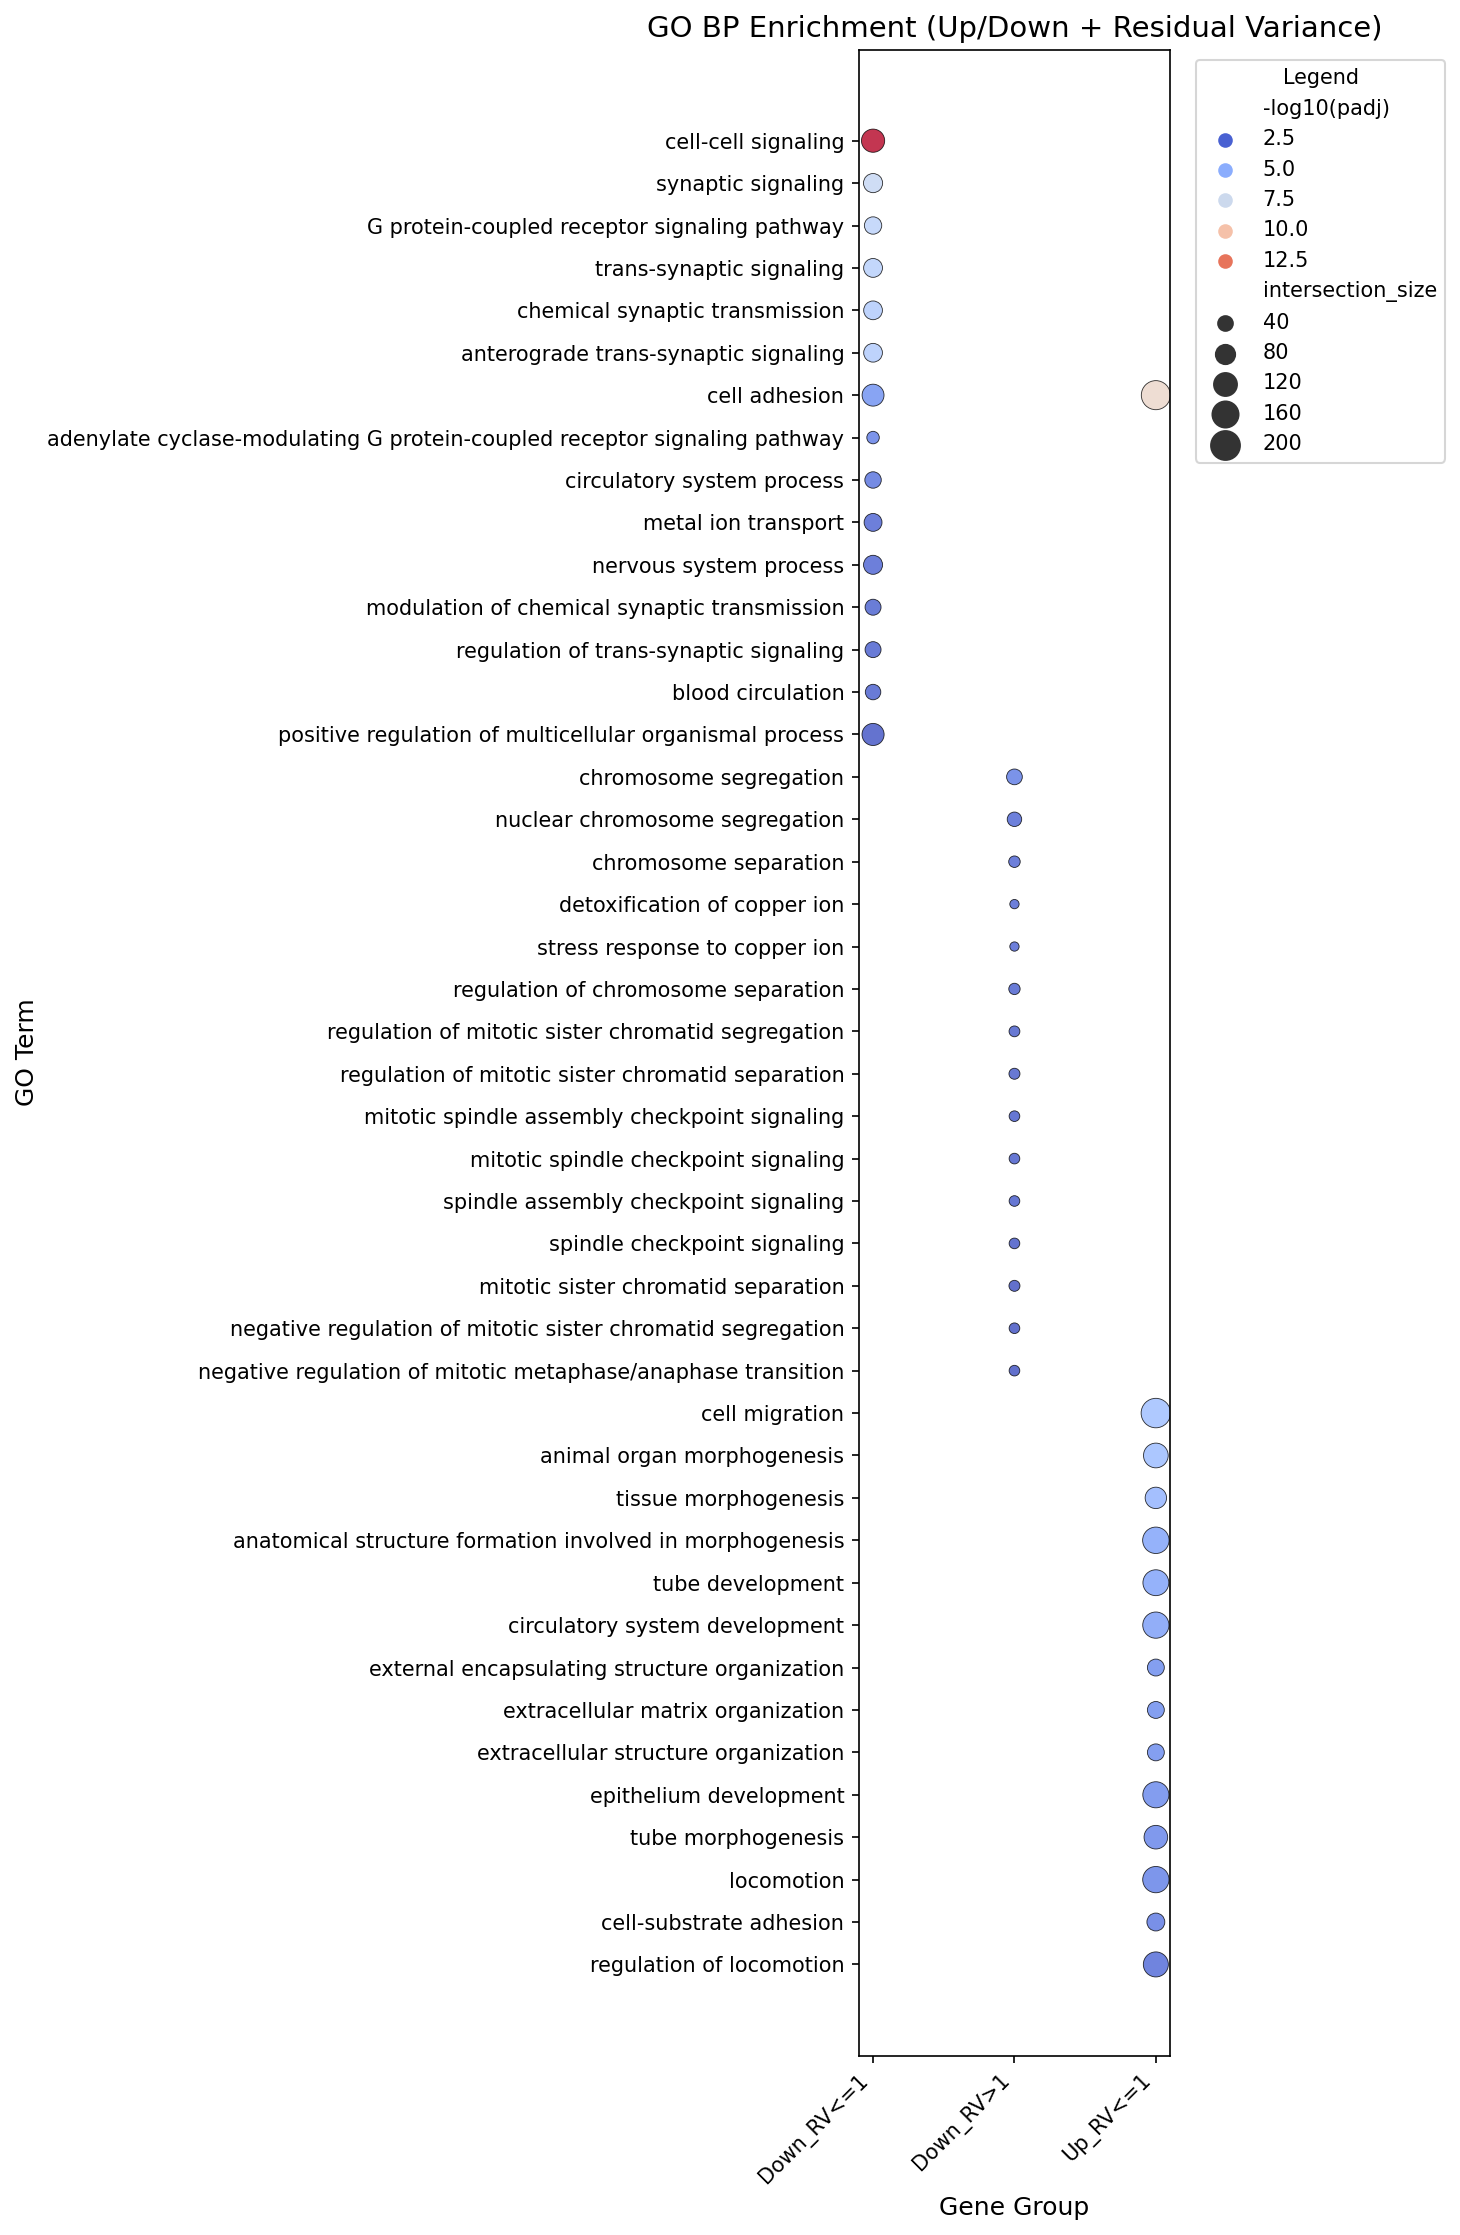

In [40]:
# Define group order explicitly
plt.figure(figsize=(8, 15), dpi=150)

sns.scatterplot(
    data=top_combined,
    x='Group',                 # Use 'Group', not 'category'
    y='name',
    size='intersection_size',
    hue='-log10(padj)',
    palette='coolwarm',        # Blue to orange
    sizes=(20, 200),
    edgecolor='black',
    alpha=0.8,
    legend='brief'
)

plt.title("GO BP Enrichment (Up/Down + Residual Variance)", fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.ylabel("GO Term", fontsize=12)
plt.xlabel("Gene Group", fontsize=12)
plt.tight_layout()
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Legend")

plt.savefig("/home/xiangru.huo-umw/scHiC/scripts/plot2/GO_analysis_RV_up_down_4groups.pdf", format='pdf')
plt.show()